In [46]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import pickle
from itertools import product
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from adjustText import adjust_text

In [47]:
def load_pickle(path): 

    with open(path, "rb") as f: 
        return pickle.load(f)

In [48]:
REPO_DIR = Path("/data/rbg/users/ashyamal/RNA-FM-benchmarking")
BASE = REPO_DIR / "model_outputs"
OUT_DIR = REPO_DIR / "benchmarking_results"
FIGURE_DIR = REPO_DIR / "paper_figures"
EMB_DIR = REPO_DIR / "data" / "RNA_embeddings"

DATASETS = ["TCGA", "Hartwig", "CPTAC", "TARGET_AML"]
n_datasets = len(DATASETS)

FM_BULK = {"BulkRNABert", "BulkFormer", "COMPASS"}
FM_SC   = {"scGPT", "STATE", "CancerFoundation", "UCE"}
FM_ALL  = FM_BULK | FM_SC

dataset_labels = {"TARGET_AML": "TARGET-AML"}

dataset_colors = {
    "TCGA":       "#4C72B0",
    "Hartwig":    "#DD8452",
    "CPTAC":      "#55A868",
    "TARGET_AML": "#C44E52",
}

In [49]:
def get_cancer_type_info_from_embeddings(dataset, cancer_types=None):
    suffix = "_cleaned" if dataset == "TCGA" else ""
    embeddings = load_pickle(EMB_DIR / f"{dataset}_processed{suffix}.pkl")
    
    cancer_type_value_counts = {}
    for pid in embeddings:
        cancer_type = embeddings[pid]["cancer_type"]
        cancer_type_value_counts[cancer_type] = cancer_type_value_counts.get(cancer_type, 0) + 1
    total = sum(cancer_type_value_counts.values())
    
    if cancer_types is None:
        return cancer_type_value_counts
    
    fraction = 0
    for ct in cancer_types:
        fraction += cancer_type_value_counts.get(ct, 0) / total
    return fraction

In [50]:
def select_best_arch_loss_by_val(dataset):
    """
    For each (RNA_key, nHVGs): pick the (arch, loss) with highest mean val C-index
    across all seeds and splits. Returns DataFrame with [RNA_key, nHVGs, arch, loss].
    """
    val_df = pd.read_csv(BASE / dataset / "survival" / "PFS" / "val_metrics.csv")
    val_df["nHVGs"] = val_df["nHVGs"].fillna("None").astype(str)

    val_mean = (
        val_df.dropna(subset=["val_cindex"])
        .groupby(["RNA_key", "nHVGs", "arch", "loss"])["val_cindex"]
        .mean()
        .reset_index()
    )
    best = (
        val_mean.sort_values("val_cindex", ascending=False)
        .groupby(["RNA_key", "nHVGs"], as_index=False)
        .head(1)[["RNA_key", "nHVGs", "arch", "loss"]]
    )
    return best

In [51]:
group_cols = ["dataset", "task", "arch", "loss", "RNA_key", "nHVGs"]

for dataset in DATASETS:
    csv = BASE / dataset / "survival" / "PFS" / "all_metrics.csv"
    if not csv.exists():
        print(f"Missing: {csv}")
        continue

    df = pd.read_csv(csv)
    df["nHVGs"] = df["nHVGs"].fillna("None")
    print(f"\n{dataset}: {len(df)} rows, {df['overall'].isna().sum()} NaN overall")
    # print NaN rows
    nan_rows = df[df["overall"].isna()]
    print(nan_rows[group_cols + ["overall"]])
    
    error_rows = df[df["error"].notna()]
    print(f"{len(error_rows)} rows with errors:")

    exclude = set(group_cols + ["seed", "split", "run_dir", "error"])
    metric_cols = [c for c in df.columns if c not in exclude]

    agg_dict = {f"{col}_mean": (col, "mean") for col in metric_cols}
    agg_dict.update({f"{col}_std": (col, "std") for col in metric_cols})
    agg_dict["n_runs"] = ("overall", "count")

    df_agg = (
        df.dropna(subset=["overall"])
        .groupby(group_cols)
        .agg(**agg_dict)
        .reset_index()
        .sort_values("overall_mean", ascending=False)
    )

    out_path = OUT_DIR / "transcriptomic" / f"{dataset}_survival_PFS_agg.csv"
    df_agg.to_csv(out_path, index=False)
    print(f"Wrote {len(df_agg)} rows to {out_path}")


TCGA: 1280 rows, 0 NaN overall
Empty DataFrame
Columns: [dataset, task, arch, loss, RNA_key, nHVGs, overall]
Index: []
0 rows with errors:
Wrote 128 rows to /data/rbg/users/ashyamal/RNA-FM-benchmarking/benchmarking_results/transcriptomic/TCGA_survival_PFS_agg.csv

Hartwig: 1280 rows, 0 NaN overall
Empty DataFrame
Columns: [dataset, task, arch, loss, RNA_key, nHVGs, overall]
Index: []
0 rows with errors:
Wrote 128 rows to /data/rbg/users/ashyamal/RNA-FM-benchmarking/benchmarking_results/transcriptomic/Hartwig_survival_PFS_agg.csv

CPTAC: 1280 rows, 0 NaN overall
Empty DataFrame
Columns: [dataset, task, arch, loss, RNA_key, nHVGs, overall]
Index: []
0 rows with errors:
Wrote 128 rows to /data/rbg/users/ashyamal/RNA-FM-benchmarking/benchmarking_results/transcriptomic/CPTAC_survival_PFS_agg.csv

TARGET_AML: 1280 rows, 0 NaN overall
Empty DataFrame
Columns: [dataset, task, arch, loss, RNA_key, nHVGs, overall]
Index: []
0 rows with errors:
Wrote 128 rows to /data/rbg/users/ashyamal/RNA-FM-b

In [52]:
def build_filtered_agg(dataset):
    """Merge agg CSV with val-selected (arch, loss) + val C-index for nHVGs selection."""
    df = pd.read_csv(OUT_DIR / "transcriptomic" / f"{dataset}_survival_PFS_agg.csv")
    df["nHVGs"] = df["nHVGs"].fillna("None").astype(str)

    val_df = pd.read_csv(BASE / dataset / "survival" / "PFS" / "val_metrics.csv")
    val_df["nHVGs"] = val_df["nHVGs"].fillna("None").astype(str)
    val_mean = (
        val_df.dropna(subset=["val_cindex"])
        .groupby(["RNA_key", "nHVGs", "arch", "loss"])["val_cindex"]
        .mean().reset_index()
        .rename(columns={"val_cindex": "val_cindex_mean"})
    )
    best = (
        val_mean.sort_values("val_cindex_mean", ascending=False)
        .groupby(["RNA_key", "nHVGs"], as_index=False)
        .head(1)
    )  # columns: RNA_key, nHVGs, arch, loss, val_cindex_mean
    df = df.merge(best, on=["RNA_key", "nHVGs", "arch", "loss"])
    df.to_csv(OUT_DIR / "transcriptomic" / f"{dataset}_survival_PFS_agg_filtered.csv", index=False)
    return df

for d in DATASETS:
    build_filtered_agg(d)

In [53]:
def categorize_row(rna_key: str, nHVGs) -> str:
    rk = str(rna_key)
    if rk in FM_BULK:
        return "FM_BULK"
    if rk in FM_SC:
        return "FM_SC"
    if rk.startswith("max_") or rk.startswith("ssGSEA_"):
        return "GS"
    if rk in ("PCA_50", "PCA_100"):
        return "PCA"
    if rk == "RNA_seq":
        if str(nHVGs) in ("None", "nan", ""):
            return "Raw_expression"
        return "HVG"
    return "Other"

def summarize_best_per_category(df: pd.DataFrame, verbose: bool = False) -> pd.DataFrame:
    df = df.copy()
    df["overall_mean"]    = pd.to_numeric(df["overall_mean"],    errors="coerce")
    df["overall_std"]     = pd.to_numeric(df["overall_std"],     errors="coerce")
    df["nHVGs"]           = df["nHVGs"].fillna("None").astype(str)
    df["category"]        = df.apply(lambda r: categorize_row(r["RNA_key"], r["nHVGs"]), axis=1)

    if verbose:
        df["category"] = df.apply(
            lambda r: r["RNA_key"] if r["category"] in ("FM_BULK", "FM_SC") else r["category"], axis=1
        )
        allowed = FM_ALL | {"GS", "PCA", "Raw_expression", "HVG"}
        order = ["BulkRNABert", "BulkFormer", "COMPASS", "scGPT", "STATE", "CancerFoundation", "UCE",
                 "GS", "HVG", "PCA", "Raw_expression"]
    else:
        allowed = {"FM_BULK", "FM_SC", "GS", "PCA", "Raw_expression", "HVG"}
        order = ["FM_BULK", "FM_SC", "GS", "HVG", "PCA", "Raw_expression"]

    df = df[df["category"].isin(allowed)].dropna(subset=["overall_mean"])

    # Use val C-index for nHVGs selection (avoids test-set leakage); fall back to test if absent
    if "val_cindex_mean" in df.columns and df["val_cindex_mean"].notna().any():
        df["val_cindex_mean"] = pd.to_numeric(df["val_cindex_mean"], errors="coerce")
        sort_col = "val_cindex_mean"
    else:
        sort_col = "overall_mean"

    df_sorted = df.sort_values(
        by=["category", sort_col, "overall_std", "arch", "loss", "RNA_key", "nHVGs"],
        ascending=[True, False, True, True, True, True, True],
        kind="mergesort",
    )
    best = df_sorted.groupby("category", as_index=False).head(1)

    out = best[["category", "overall_mean", "overall_std", "arch", "loss", "RNA_key", "nHVGs"]].rename(
        columns={"overall_mean": "best_cindex_mean", "overall_std": "best_cindex_std"}
    )
    out["category"] = pd.Categorical(out["category"], categories=order, ordered=True)
    return out.sort_values("category").reset_index(drop=True)

def run_agg(verbose=True):
    for d in DATASETS:
        df = pd.read_csv(OUT_DIR / "transcriptomic" / f"{d}_survival_PFS_agg_filtered.csv")
        summary = summarize_best_per_category(df, verbose=verbose)
        print(f"\n{'='*80}\nDataset: {d}\n{'='*80}")
        print(summary.to_string(index=False))

run_agg()



Dataset: TCGA
        category  best_cindex_mean  best_cindex_std        arch   loss          RNA_key  nHVGs
     BulkRNABert          0.723639         0.009901 ResidualMLP    Cox      BulkRNABert   None
      BulkFormer          0.716180         0.014934 ResidualMLP CIndex       BulkFormer   None
         COMPASS          0.710862         0.013073 ResidualMLP    Cox          COMPASS   None
           scGPT          0.683241         0.007495      Linear    Cox            scGPT   None
           STATE          0.728183         0.012668 ResidualMLP    Cox            STATE   None
CancerFoundation          0.691970         0.007966      Linear    Cox CancerFoundation   None
             UCE          0.676881         0.012288      Linear    Cox              UCE   None
              GS          0.737289         0.012883 ResidualMLP CIndex     max_combined   None
             HVG          0.741543         0.010578 ResidualMLP CIndex          RNA_seq 5000.0
             PCA          0.733908 

In [54]:
run_agg(verbose=False)


Dataset: TCGA
      category  best_cindex_mean  best_cindex_std        arch   loss      RNA_key  nHVGs
       FM_BULK          0.723639         0.009901 ResidualMLP    Cox  BulkRNABert   None
         FM_SC          0.728183         0.012668 ResidualMLP    Cox        STATE   None
            GS          0.737289         0.012883 ResidualMLP CIndex max_combined   None
           HVG          0.741543         0.010578 ResidualMLP CIndex      RNA_seq 5000.0
           PCA          0.733908         0.009565 ResidualMLP CIndex      PCA_100   None
Raw_expression          0.740869         0.010690      Linear CIndex      RNA_seq   None

Dataset: Hartwig
      category  best_cindex_mean  best_cindex_std        arch   loss         RNA_key  nHVGs
       FM_BULK          0.587038         0.018914      Linear CIndex      BulkFormer   None
         FM_SC          0.609626         0.018532      Linear    Cox           STATE   None
            GS          0.614613         0.027719      Linear CIndex

### Per cancer type results

In [55]:
def load_all_agg(verbose: bool = False):
    dfs = []
    for d in DATASETS:
        x = pd.read_csv(OUT_DIR / "transcriptomic" / f"{d}_survival_PFS_agg_filtered.csv")
        x["dataset"] = d
        x["category"] = x.apply(lambda r: categorize_row(r["RNA_key"], r["nHVGs"]), axis=1)

        if verbose:
            x["category"] = x.apply(
                lambda r: r["RNA_key"] if r["category"] in ("FM_BULK","FM_SC") else r["category"], axis=1
            )
            allowed = FM_ALL | {"GS","PCA","Raw_expression","HVG"}
            order = ["BulkRNABert","BulkFormer","COMPASS","scGPT","STATE","CancerFoundation","UCE",
                     "GS","HVG","PCA","Raw_expression"]
        else:
            allowed = {"FM_BULK","FM_SC","GS","PCA","Raw_expression","HVG"}
            order = ["FM_BULK","FM_SC","GS","HVG","PCA","Raw_expression"]

        x = x[x["category"].isin(allowed)].copy()
        x["category"] = pd.Categorical(x["category"], categories=order, ordered=True)
        dfs.append(x)

    df_all = pd.concat(dfs, ignore_index=True)
    return df_all

df_all = load_all_agg(verbose=False)
df_all.shape, df_all["dataset"].value_counts()

((128, 211),
 dataset
 TCGA          32
 Hartwig       32
 CPTAC         32
 TARGET_AML    32
 Name: count, dtype: int64)

In [56]:
df_all.head()

,dataset,task,arch,loss,RNA_key,nHVGs,overall_mean,ACC_mean,BLCA_mean,BRCA_mean,...,"Larynx, NOS_std","Lip, NOS_std","Lung, NOS_std","Oropharynx, NOS_std","Overlapping lesion of lip, oral cavity and pharynx_std","Pancreas, NOS_std","Tongue, NOS_std","Uterus, NOS_std",AML_mean,AML_std
0,TCGA,survival,ResidualMLP,CIndex,RNA_seq,5000.0,0.741543,0.805013,0.633859,0.669230,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,TCGA,survival,ResidualMLP,CIndex,RNA_seq,10000.0,0.741094,0.818521,0.616903,0.670384,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,TCGA,survival,Linear,CIndex,RNA_seq,NaN,0.740869,0.823811,0.637976,0.673765,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,TCGA,survival,ResidualMLP,CIndex,RNA_seq,2058.0,0.739227,0.811370,0.631521,0.660027,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,TCGA,survival,ResidualMLP,CIndex,RNA_seq,1250.0,0.738713,0.799825,0.633707,0.663247,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [57]:
# Infer cancer-type metric bases from "*_mean" columns (excluding overall)
mean_cols = [c for c in df_all.columns if c.endswith("_mean")]
cancer_bases = sorted({c[:-5] for c in mean_cols if c not in ("overall_mean","val_cindex_mean")})

print(f"Found {len(cancer_bases)} cancer types:")
print(f"Example cancer types: {cancer_bases[:10]}")

Found 100 cancer types:
Example cancer types: ['ACC', 'AML', 'Adenocarcinoma', 'Adenocarcinoma, diffuse/signet ring cell', 'Adenocarcinoma, intestinal type', 'Angiosarcoma', 'BLCA', 'BRCA', 'Basal cell carcinoma', 'Base of tongue, NOS']


In [58]:
rows = []
id_cols = ["dataset","task","arch","loss","RNA_key","nHVGs","category"]

for base in cancer_bases:
    mcol, scol = f"{base}_mean", f"{base}_std"
    if mcol not in df_all.columns: 
        continue

    tmp = df_all[id_cols + [mcol] + ([scol] if scol in df_all.columns else [])].copy()
    tmp = tmp.rename(columns={mcol: "cindex_mean", scol: "cindex_std"} if scol in tmp.columns else {mcol:"cindex_mean"})
    tmp["cancer_type"] = base

    tmp["cindex_mean"] = pd.to_numeric(tmp["cindex_mean"], errors="coerce")
    if "cindex_std" in tmp.columns:
        tmp["cindex_std"] = pd.to_numeric(tmp["cindex_std"], errors="coerce")
    else:
        tmp["cindex_std"] = np.nan

    # Choose best within (dataset, cancer_type, category); tie-break by lower std then deterministic keys
    tmp = tmp.dropna(subset=["cindex_mean"]).sort_values(
        by=["dataset","cancer_type","category","cindex_mean","cindex_std","arch","loss","RNA_key","nHVGs"],
        ascending=[True, True, True, False, True, True, True, True, True],
        kind="mergesort"
    )
    best = tmp.groupby(["dataset","cancer_type","category"], as_index=False, observed=True).head(1)

    rows.append(best)

best_long = pd.concat(rows, ignore_index=True).sort_values(["dataset","cancer_type","category"])
best_long.reset_index(drop=True, inplace=True)

best_long.head()

,dataset,task,arch,loss,RNA_key,nHVGs,category,cindex_mean,cindex_std,cancer_type
0,CPTAC,survival,Linear,Cox,BulkFormer,NaN,FM_BULK,0.561897,0.025537,"Brain, NOS"
1,CPTAC,survival,Linear,Cox,scGPT,NaN,FM_SC,0.574103,0.070898,"Brain, NOS"
2,CPTAC,survival,ResidualMLP,Cox,max_AURORA,NaN,GS,0.596562,0.049949,"Brain, NOS"
3,CPTAC,survival,ResidualMLP,CIndex,RNA_seq,10000.0,HVG,0.577776,0.049895,"Brain, NOS"
4,CPTAC,survival,ResidualMLP,Cox,PCA_50,NaN,PCA,0.534210,0.084177,"Brain, NOS"


In [59]:
def heatmap_for_dataset(best_long: pd.DataFrame, dataset: str):
    x = best_long[best_long["dataset"] == dataset].copy()
    mat = x.pivot_table(index="cancer_type", columns="category", values="cindex_mean", aggfunc="first", observed=True)
    return x, mat

heatmaps = {}
for d in best_long["dataset"].unique():
    # Only generate heatmaps for TCGA and CPTAC
    # Hartwig has many cancer types (57)
    # TARGET_AML has only one cancer type (AML)
    if d in ["TCGA", "CPTAC"]:
        _, mat = heatmap_for_dataset(best_long, d)
        heatmaps[d] = mat
        print(d, mat.shape)

CPTAC (9, 6)
TCGA (33, 6)


In [60]:
def plot_heatmap(mat: pd.DataFrame, dataset: str):
    
    mat = mat.dropna(how="all")

    cell_size = 1
    fig_w = cell_size * mat.shape[1]
    fig_h = cell_size * mat.shape[0]

    # Build colormap
    colors = plt.cm.viridis(np.linspace(0.0, 0.75, 256))  # cut off the yellow end
    cmap = mcolors.LinearSegmentedColormap.from_list('viridis_dark', colors)
    
    # Build labels: "CancerType\n(N=123)"
    ct_counts = get_cancer_type_info_from_embeddings(dataset)

    # Sort rows by descending patient count
    sorted_index = sorted(mat.index, key=lambda ct: ct_counts.get(ct, 0), reverse=True)
    mat = mat.loc[sorted_index]
    
    yticklabels = [f"{ct.split(', NOS')[0]}\n(N={ct_counts.get(ct, 0)})" for ct in mat.index]
    
    plt.figure(figsize=(fig_w, fig_h))
    plt.imshow(mat.values, aspect="equal", cmap=cmap, vmin=0.5, vmax=0.89)

    plt.title(f"{dataset}: Best model per category")
    plt.colorbar(label="Best mean C-index")
    
    plt.xticks(range(mat.shape[1]), mat.columns.astype(str), rotation=45, ha="right")
    plt.yticks(range(mat.shape[0]), yticklabels)
    
    # Plot values on cells
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            val = mat.iat[i, j]
            if pd.notna(val):
                plt.text(j, i, f"{val:.3f}", ha="center", va="center", color="white", fontsize=8)

    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"{dataset}_per_cancer_type_heatmap.png", dpi=300)
    plt.show()

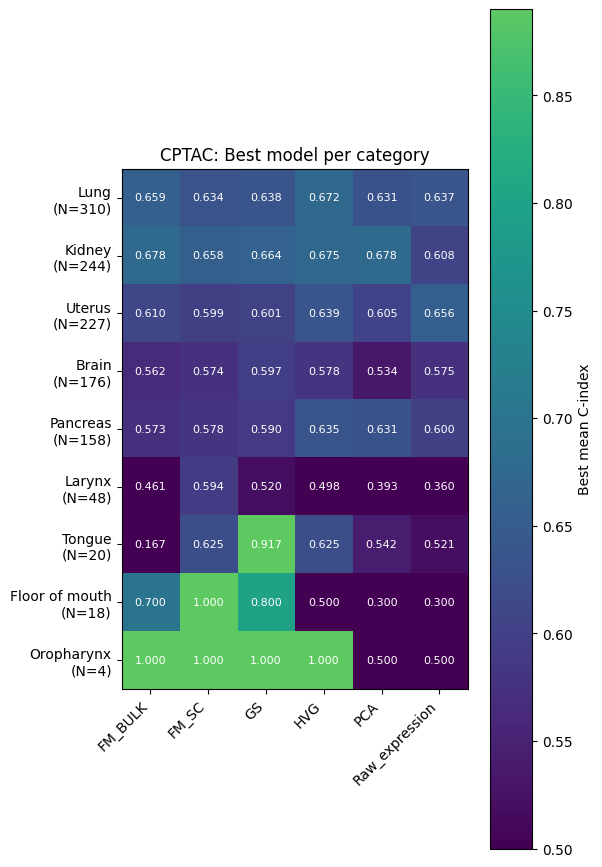

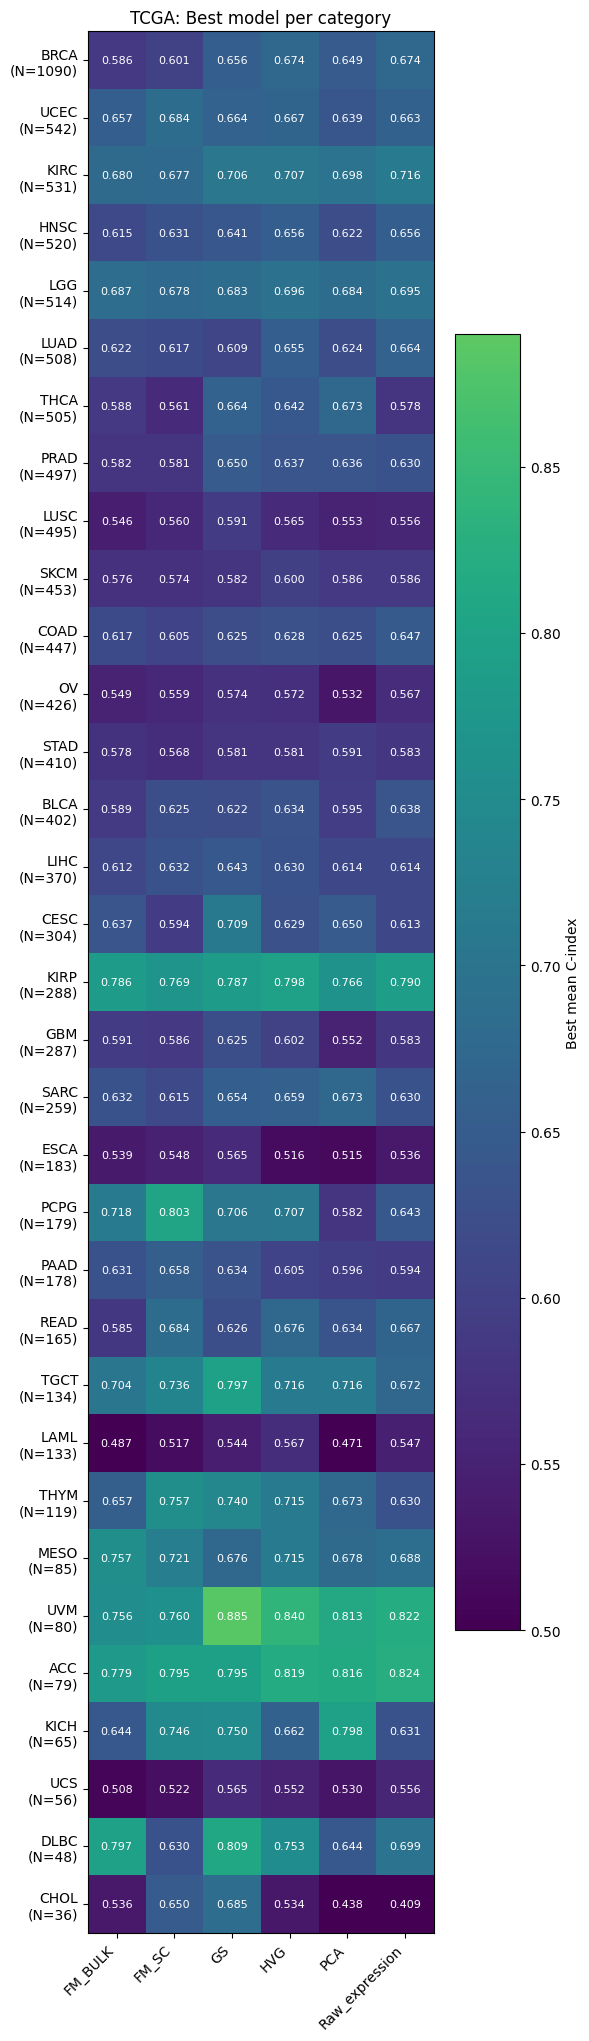

In [61]:
for d, mat in heatmaps.items():
    plot_heatmap(mat, d)

In [62]:
winners = (
    best_long.assign(winner=lambda x: x["RNA_key"].astype(str) + " | " + x["arch"].astype(str) + " | " + x["loss"].astype(str) + " | nHVGs=" + x["nHVGs"].astype(str))
    .pivot_table(index=["dataset","cancer_type"], columns="category", values="winner", aggfunc="first", observed=True)
)

winners

category                                                            FM_BULK  \
dataset cancer_type                                                           
CPTAC   Brain, NOS                    BulkFormer | Linear | Cox | nHVGs=nan   
        Floor of mouth, NOS           BulkFormer | Linear | Cox | nHVGs=nan   
        Kidney, NOS              COMPASS | ResidualMLP | CIndex | nHVGs=nan   
        Larynx, NOS          BulkRNABert | ResidualMLP | CIndex | nHVGs=nan   
        Lung, NOS            BulkRNABert | ResidualMLP | CIndex | nHVGs=nan   
...                                                                     ...   
TCGA    THCA                  BulkFormer | ResidualMLP | CIndex | nHVGs=nan   
        THYM                        COMPASS | ResidualMLP | Cox | nHVGs=nan   
        UCEC                    BulkRNABert | ResidualMLP | Cox | nHVGs=nan   
        UCS                   BulkFormer | ResidualMLP | CIndex | nHVGs=nan   
        UVM                   BulkFormer | ResidualMLP | CIndex | nHVGs=nan   

category                                                              FM_SC  \
dataset cancer_type                                                           
CPTAC   Brain, NOS                         scGPT | Linear | Cox | nHVGs=nan   
        Floor of mouth, NOS  CancerFoundation | Linear | CIndex | nHVGs=nan   
        Kidney, NOS                        STATE | Linear | Cox | nHVGs=nan   
        Larynx, NOS                       UCE | Linear | CIndex | nHVGs=nan   
        Lung, NOS                          STATE | Linear | Cox | nHVGs=nan   
...                                                                     ...   
TCGA    THCA                          STATE | ResidualMLP | Cox | nHVGs=nan   
        THYM                          STATE | ResidualMLP | Cox | nHVGs=nan   
        UCEC                          STATE | ResidualMLP | Cox | nHVGs=nan   
        UCS                                scGPT | Linear | Cox | nHVGs=nan   
        UVM                           STATE | ResidualMLP | Cox | nHVGs=nan   

category                                                                   GS  \
dataset cancer_type                                                             
CPTAC   Brain, NOS                 max_AURORA | ResidualMLP | Cox | nHVGs=nan   
        Floor of mouth, NOS     ssGSEA_hallmark | Linear | CIndex | nHVGs=nan   
        Kidney, NOS             ssGSEA_immuno | ResidualMLP | Cox | nHVGs=nan   
        Larynx, NOS             max_immuno | ResidualMLP | CIndex | nHVGs=nan   
        Lung, NOS                max_combined | ResidualMLP | Cox | nHVGs=nan   
...                                                                       ...   
TCGA    THCA                  max_combined | ResidualMLP | CIndex | nHVGs=nan   
        THYM                     max_hallmark | ResidualMLP | Cox | nHVGs=nan   
        UCEC                    max_AURORA | ResidualMLP | CIndex | nHVGs=nan   
        UCS                  ssGSEA_AURORA | ResidualMLP | CIndex | nHVGs=nan   
        UVM                   max_combined | ResidualMLP | CIndex | nHVGs=nan   

category                                                                HVG  \
dataset cancer_type                                                           
CPTAC   Brain, NOS           RNA_seq | ResidualMLP | CIndex | nHVGs=10000.0   
        Floor of mouth, NOS       RNA_seq | ResidualMLP | Cox | nHVGs=132.0   
        Kidney, NOS               RNA_seq | ResidualMLP | Cox | nHVGs=729.0   
        Larynx, NOS                RNA_seq | ResidualMLP | Cox | nHVGs=18.0   
        Lung, NOS                 RNA_seq | ResidualMLP | Cox | nHVGs=640.0   
...                                                                     ...   
TCGA    THCA                  RNA_seq | ResidualMLP | CIndex | nHVGs=5000.0   
        THYM                   RNA_seq | ResidualMLP | CIndex | nHVGs=640.0   
        UCEC                 RNA_seq | ResidualMLP | CIndex | nHVGs=10000.0   
        UCS          

In [63]:
fm_cats = {"FM_BULK", "FM_SC"}
baseline_cats = {"GS", "HVG", "PCA", "Raw_expression"}

rows = []

for (dataset, cancer), g in best_long.groupby(["dataset", "cancer_type"]):

    fm_best = g[g["category"].isin(fm_cats)]["cindex_mean"].max()
    base_best = g[g["category"].isin(baseline_cats)]["cindex_mean"].max()

    rows.append({
        "dataset": dataset,
        "cancer_type": cancer,
        "fm_best": fm_best,
        "baseline_best": base_best,
        "fm_beats_baseline": fm_best > base_best
    })

fm_vs_baseline = pd.DataFrame(rows)
fm_vs_baseline.head()

,dataset,cancer_type,fm_best,baseline_best,fm_beats_baseline
0,CPTAC,"Brain, NOS",0.574103,0.596562,False
1,CPTAC,"Floor of mouth, NOS",1.000000,0.800000,True
2,CPTAC,"Kidney, NOS",0.677660,0.677910,False
3,CPTAC,"Larynx, NOS",0.593736,0.520073,True
4,CPTAC,"Lung, NOS",0.658630,0.672359,False


In [64]:
fm_vs_baseline = fm_vs_baseline[fm_vs_baseline["cancer_type"] != "overall"]
summary = (
    fm_vs_baseline
    .groupby("dataset")
    .agg(
        n_cancer_types=("cancer_type", "count"),
        n_fm_wins=("fm_beats_baseline", "sum"),
        cancer_types_where_fm_wins=("cancer_type", lambda x: list(
            x[fm_vs_baseline.loc[x.index, "fm_beats_baseline"]]
        ))
    )
)

summary["fraction of patients in winning cancer types"] = summary.apply(
    lambda row: get_cancer_type_info_from_embeddings(row.name, row["cancer_types_where_fm_wins"]),
    axis=1
)

summary

,n_cancer_types,n_fm_wins,cancer_types_where_fm_wins,fraction of patients in winning cancer types
dataset,,,,
CPTAC,9,2,"[Floor of mouth, NOS, Larynx, NOS]",0.054010
Hartwig,22,3,"[Melanoma, Mesothelioma, Non-small cell carcin...",0.123656
TARGET_AML,1,0,[],0.000000
TCGA,33,6,"[MESO, PAAD, PCPG, READ, THYM, UCEC]",0.122064


In [65]:
summary.to_csv(OUT_DIR / "transcriptomic" / "fm_vs_baseline_cancer_type_summary.csv")

#### TCGA

Baseline wins: 27 / 33 cancer types
Winning baseline category counts:
winning_baseline
GS                12
HVG                5
PCA                4
Raw_expression     6


/tmp/ipykernel_2790903/14747615.py:46: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.loc[g["cindex_mean"].idxmax(), "category"])


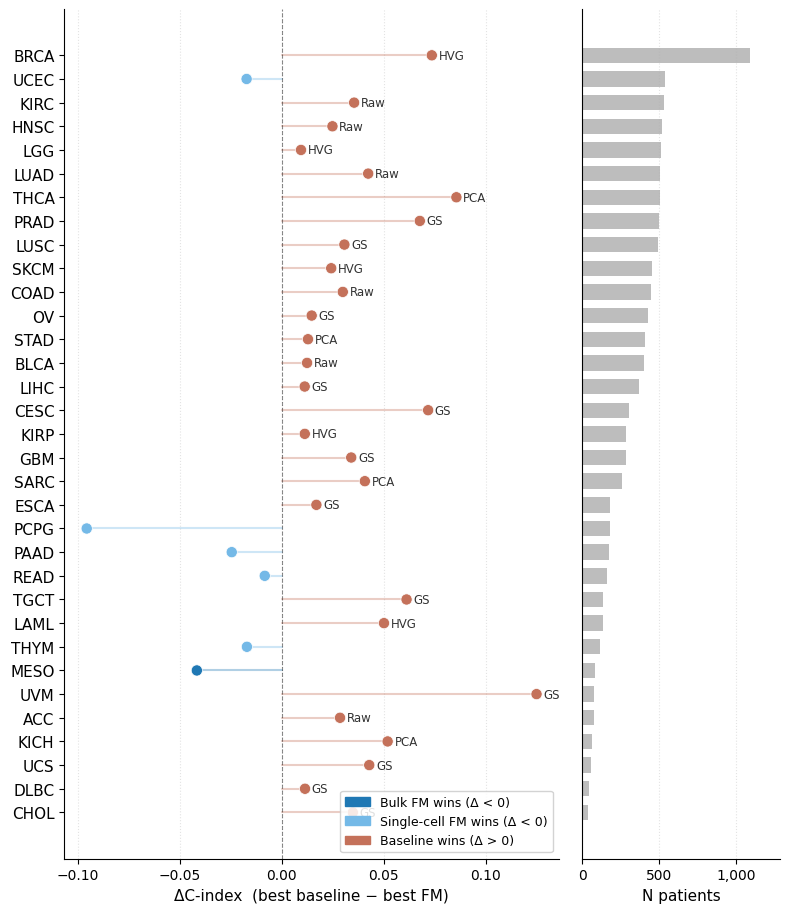

In [66]:
# ── TCGA ΔC-index dot plot (best baseline − best FM) ──────────────────────────
MIN_N = 0  # raise to filter out low-N cancer types

FM_CATS       = {"FM_BULK", "FM_SC"}
BASELINE_CATS = {"GS", "HVG", "PCA", "Raw_expression"}

tcga = best_long[best_long["dataset"] == "TCGA"].copy()

best_fm = (tcga[tcga["category"].isin(FM_CATS)]
           .groupby("cancer_type")["cindex_mean"].max()
           .rename("best_fm"))

best_base_rows = (
    tcga[tcga["category"].isin(BASELINE_CATS)]
    .loc[lambda df: df.groupby("cancer_type")["cindex_mean"].idxmax()]
    .set_index("cancer_type")
)

best_base = best_base_rows["cindex_mean"].rename("best_baseline")
winning_baseline = best_base_rows["category"].rename("winning_baseline")

delta = pd.concat([best_fm, best_base], axis=1).dropna()
delta["delta"] = delta["best_baseline"] - delta["best_fm"]
delta = delta.join(winning_baseline)

ct_counts   = get_cancer_type_info_from_embeddings("TCGA")
delta["N"]  = delta.index.map(lambda ct: ct_counts.get(ct, 0))
delta       = delta[delta["N"] >= MIN_N].sort_values("N", ascending=True)

# ── print baseline win breakdown ──────────────────────────────────────────────
baseline_wins = delta[delta["delta"] > 0]  # use >= 0 if you want ties counted

baseline_win_counts = (
    baseline_wins["winning_baseline"]
    .value_counts()
    .reindex(sorted(BASELINE_CATS), fill_value=0)
)

print(f"Baseline wins: {len(baseline_wins)} / {len(delta)} cancer types")
print("Winning baseline category counts:")
print(baseline_win_counts.to_string())

# ── colours ───────────────────────────────────────────────────────────────────
winning_fm = (tcga[tcga["category"].isin(FM_CATS)]
              .groupby("cancer_type")
              .apply(lambda g: g.loc[g["cindex_mean"].idxmax(), "category"])
              .rename("winning_fm"))
delta = delta.join(winning_fm)

FM_BULK_COL = '#1F78B4'
FM_SC_COL   = '#74B9E7'
BASE_COL    = '#C4715A'

def row_color(r):
    if r["delta"] >= 0:
        return BASE_COL
    return FM_BULK_COL if r["winning_fm"] == "FM_BULK" else FM_SC_COL

colors = [row_color(r) for _, r in delta.iterrows()]
y_pos  = np.arange(len(delta))

# ── figure ────────────────────────────────────────────────────────────────────
fig, (ax, ax_n) = plt.subplots(
    1, 2,
    figsize=(8, max(5, 0.28 * len(delta))),
    gridspec_kw={"width_ratios": [2.5, 1]},
    sharey=True,
)

for y, d, c in zip(y_pos, delta["delta"], colors):
    ax.plot([0, d], [y, y], color=c, alpha=0.35, lw=1.5, solid_capstyle="round")

ax.scatter(delta["delta"], y_pos, color=colors, s=65, zorder=3,
           edgecolors="white", linewidths=0.5)

# annotate winning baseline category for baseline wins
CATEGORY_LABELS = {
    "HVG": "HVG",
    "GS": "GS",
    "PCA": "PCA",
    "Raw_expression": "Raw"
}

x_range = delta["delta"].max() - delta["delta"].min()
x_offset = 0.015 * x_range  # small spacing to right of dot

for y, (_, row) in zip(y_pos, delta.iterrows()):
    if row["delta"] > 0:  # only annotate baseline wins
        ax.text(
            row["delta"] + x_offset,
            y,
            CATEGORY_LABELS.get(row["winning_baseline"], row["winning_baseline"]),
            va="center",
            ha="left",
            fontsize=8.5,
            color="black",
            alpha=0.8,
        )

ax.axvline(0, color="black", lw=0.8, ls="--", alpha=0.45)
ax.set_yticks(y_pos)
ax.set_yticklabels([ct.split(", NOS")[0] for ct in delta.index], fontsize=11)
ax.set_xlabel("ΔC-index  (best baseline − best FM)", fontsize=11)
ax.grid(axis="x", ls=":", alpha=0.35)
ax.spines[["top", "right"]].set_visible(False)

legend_handles = [
    mpatches.Patch(color=FM_BULK_COL, label="Bulk FM wins (Δ < 0)"),
    mpatches.Patch(color=FM_SC_COL,   label="Single-cell FM wins (Δ < 0)"),
    mpatches.Patch(color=BASE_COL,    label="Baseline wins (Δ > 0)"),
]
ax.legend(handles=legend_handles, fontsize=9, framealpha=0.85, loc="lower right")

# ── patient count bar panel ───────────────────────────────────────────────────
ax_n.barh(y_pos, delta["N"], color="#888888", alpha=0.55, height=0.65)
ax_n.set_xlabel("N patients", fontsize=11)
ax_n.set_xlim(0, delta["N"].max() * 1.18)
ax_n.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax_n.tick_params(axis="y", length=0)
ax_n.grid(axis="x", ls=":", alpha=0.35)
ax_n.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "TCGA_delta_cindex_dotplot.png", dpi=300, bbox_inches="tight")
plt.show()

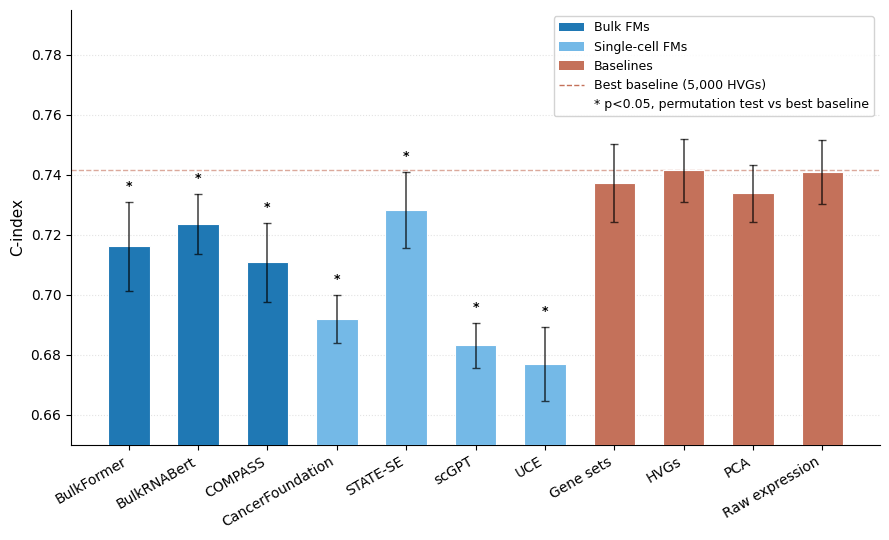

In [97]:
from matplotlib.lines import Line2D

BULK_COL = '#1F78B4'
SC_COL   = '#74B9E7'
BASE_COL = '#C4715A'

# Pull from computed DataFrames — no hardcoded values
tcga_summary = summarize_best_per_category(
    pd.read_csv(OUT_DIR / "transcriptomic" / "TCGA_survival_PFS_agg_filtered.csv"),
    verbose=True
)
tcga_lookup = tcga_summary.set_index("category")

label_to_cat = {
    'BulkFormer':       'BulkFormer',
    'BulkRNABert':      'BulkRNABert',
    'COMPASS':          'COMPASS',
    'CancerFoundation': 'CancerFoundation',
    'STATE-SE':         'STATE',
    'scGPT':            'scGPT',
    'UCE':              'UCE',
    'Gene sets':        'GS',
    'HVGs':             'HVG',
    'PCA':              'PCA',
    'Raw expression':   'Raw_expression',
}

labels = ['BulkFormer', 'BulkRNABert', 'COMPASS', 'CancerFoundation', 'STATE-SE', 'scGPT', 'UCE',
          'Gene sets', 'HVGs', 'PCA', 'Raw expression']
colors = [BULK_COL]*3 + [SC_COL]*4 + [BASE_COL]*4

means  = [float(tcga_lookup.loc[label_to_cat[l], 'best_cindex_mean']) for l in labels]
errors = [float(tcga_lookup.loc[label_to_cat[l], 'best_cindex_std'])  for l in labels]

# Best HVG config — drives both the axhline and the permutation test reference
hvg_row        = tcga_lookup.loc['HVG']
hvg_best_mean  = float(hvg_row['best_cindex_mean'])
hvg_nhvgs_str  = str(float(hvg_row['nHVGs']))       # e.g. "10000.0"
hvg_nhvgs_disp = int(float(hvg_row['nHVGs']))        # e.g. 10000

fm_key_map = {
    'BulkFormer': 'BulkFormer', 'BulkRNABert': 'BulkRNABert', 'COMPASS': 'COMPASS',
    'CancerFoundation': 'CancerFoundation', 'STATE-SE': 'STATE', 'scGPT': 'scGPT', 'UCE': 'UCE',
}

perm = pd.read_csv(OUT_DIR / "stats" / "permutation_test_results.csv")
perm["baseline_nHVGs"] = perm["baseline_nHVGs"].fillna("None").astype(str)
ref_pvals = (
    perm[(perm["dataset"] == "TCGA") &
         (perm["baseline"] == "RNA_seq") &
         (perm["baseline_nHVGs"] == hvg_nhvgs_str)]
    .set_index("fm")["p_value"]
)

def pval_stars(p):
    if p < 0.001: return "***"
    if p < 0.01:  return "**"
    if p < 0.05:  return "*"
    return "ns"

fig, ax = plt.subplots(figsize=(9, 5.5))
x = np.arange(len(labels))

ax.bar(x, means, color=colors, width=0.6, edgecolor='white', linewidth=0.8,
       yerr=errors, capsize=3, error_kw={'elinewidth': 1.2, 'alpha': 0.7}, zorder=3)
ax.axhline(y=hvg_best_mean, color=BASE_COL, linestyle='--', linewidth=1, alpha=0.6, zorder=2)
ax.set_ylim(0.65, 0.795)

for i, label in enumerate(labels):
    if label not in fm_key_map:      # baselines get no stars
        continue
    rna_key = fm_key_map[label]
    if rna_key in ref_pvals.index:
        stars = pval_stars(ref_pvals[rna_key])
        sig = stars != 'ns'
        ax.text(i, means[i] + errors[i] + 0.003, stars,
                ha='center', va='bottom', fontsize=9,
                color='black' if sig else '#aaaaaa',
                fontweight='bold' if sig else 'normal')

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=30, ha='right', fontsize=10)
ax.set_ylabel('C-index', fontsize=11)
ax.grid(axis='y', ls=':', alpha=0.35, zorder=0)
ax.spines[['top', 'right']].set_visible(False)

legend_elements = [
    mpatches.Patch(facecolor=BULK_COL, label='Bulk FMs'),
    mpatches.Patch(facecolor=SC_COL,   label='Single-cell FMs'),
    mpatches.Patch(facecolor=BASE_COL, label='Baselines'),
    Line2D([0], [0], color=BASE_COL, ls='--', lw=1, label=f'Best baseline ({hvg_nhvgs_disp:,} HVGs)'),
    Line2D([0], [0], color='none', label='* p<0.05, permutation test vs best baseline'),
]
ax.legend(handles=legend_elements, fontsize=9, framealpha=0.85, loc='upper right')

plt.tight_layout()
plt.savefig(FIGURE_DIR / 'tcga_results_bar.png', dpi=300, bbox_inches='tight')
plt.show()

### Statistical Testing

In [68]:
def sign_flip_permutation_test(diffs):
    """One-sided: P(mean >= observed) under sign flips. diffs = baseline - FM."""
    n = len(diffs)
    observed = np.mean(diffs)
    count = 0
    for signs in product([1, -1], repeat=n):
        if np.mean([s * d for s, d in zip(signs, diffs)]) >= observed:
            count += 1
    return count / (2 ** n)

def get_best_config_per_split(dataset):
    best_configs = pd.read_csv(
        OUT_DIR / "transcriptomic" / f"{dataset}_survival_PFS_agg_filtered.csv"
    )[["RNA_key", "nHVGs", "arch", "loss"]].drop_duplicates()
    best_configs["nHVGs"] = best_configs["nHVGs"].fillna("None").astype(str)

    raw = pd.read_csv(BASE / dataset / "survival" / "PFS" / "all_metrics.csv")
    raw["nHVGs"] = raw["nHVGs"].fillna("None").astype(str)

    per_split = (
        raw.merge(best_configs, on=["RNA_key", "nHVGs", "arch", "loss"])
        .dropna(subset=["overall"])
        .groupby(["RNA_key", "nHVGs", "split"])["overall"]
        .mean()
        .reset_index()
    )
    per_split["category"] = per_split.apply(
        lambda r: categorize_row(r["RNA_key"], r["nHVGs"]), axis=1
    )
    return per_split

def run_permutation_tests(verbose=True):
    
    baselines = {"GS", "HVG", "PCA", "Raw_expression"}
    fms = FM_ALL

    results = []

    for d in DATASETS:
        per_split = get_best_config_per_split(d)

        df_agg = pd.read_csv(OUT_DIR / "transcriptomic" / f"{d}_survival_PFS_agg_filtered.csv")
        summary = summarize_best_per_category(df_agg, verbose=True)

        for _, base_row in summary[summary["category"].isin(baselines)].iterrows():
            base_splits = per_split[
                (per_split["RNA_key"] == base_row["RNA_key"]) &
                (per_split["nHVGs"] == str(base_row["nHVGs"]))
            ].sort_values("split")["overall"].values

            for _, fm_row in summary[summary["category"].isin(fms)].iterrows():
                fm_splits = per_split[
                    (per_split["RNA_key"] == fm_row["RNA_key"]) &
                    (per_split["nHVGs"] == str(fm_row["nHVGs"]))
                ].sort_values("split")["overall"].values

                if len(base_splits) != 5 or len(fm_splits) != 5:
                    print(f"WARNING: {d} {base_row['RNA_key']} vs {fm_row['RNA_key']}: "
                          f"{len(base_splits)} vs {len(fm_splits)} splits")
                    continue

                diffs = base_splits - fm_splits
                p = sign_flip_permutation_test(diffs)
                results.append({
                    "dataset": d,
                    "baseline": base_row["RNA_key"],
                    "baseline_nHVGs": base_row["nHVGs"],
                    "fm": fm_row["RNA_key"],
                    "mean_diff": np.mean(diffs),
                    "p_value": p,
                    "significant": p < 0.05,
                })

    df_results = pd.DataFrame(results)
    if verbose:
        print(df_results.to_string(index=False))
    return df_results

df_perm = run_permutation_tests()
df_perm.to_csv(OUT_DIR / "stats" / "permutation_test_results.csv", index=False)

   dataset        baseline baseline_nHVGs               fm  mean_diff  p_value  significant
      TCGA    max_combined           None      BulkRNABert   0.013650  0.03125         True
      TCGA    max_combined           None       BulkFormer   0.021109  0.03125         True
      TCGA    max_combined           None          COMPASS   0.026427  0.03125         True
      TCGA    max_combined           None            scGPT   0.054048  0.03125         True
      TCGA    max_combined           None            STATE   0.009106  0.03125         True
      TCGA    max_combined           None CancerFoundation   0.045319  0.03125         True
      TCGA    max_combined           None              UCE   0.060408  0.03125         True
      TCGA         RNA_seq         5000.0      BulkRNABert   0.017904  0.03125         True
      TCGA         RNA_seq         5000.0       BulkFormer   0.025363  0.03125         True
      TCGA         RNA_seq         5000.0          COMPASS   0.030681  0.03125  

['Gene sets, Combined (max)' 'HVGs (5k)' 'PCA (100)' 'Raw expression'
 'Gene sets, AURORA (max)' 'HVGs (10k)']


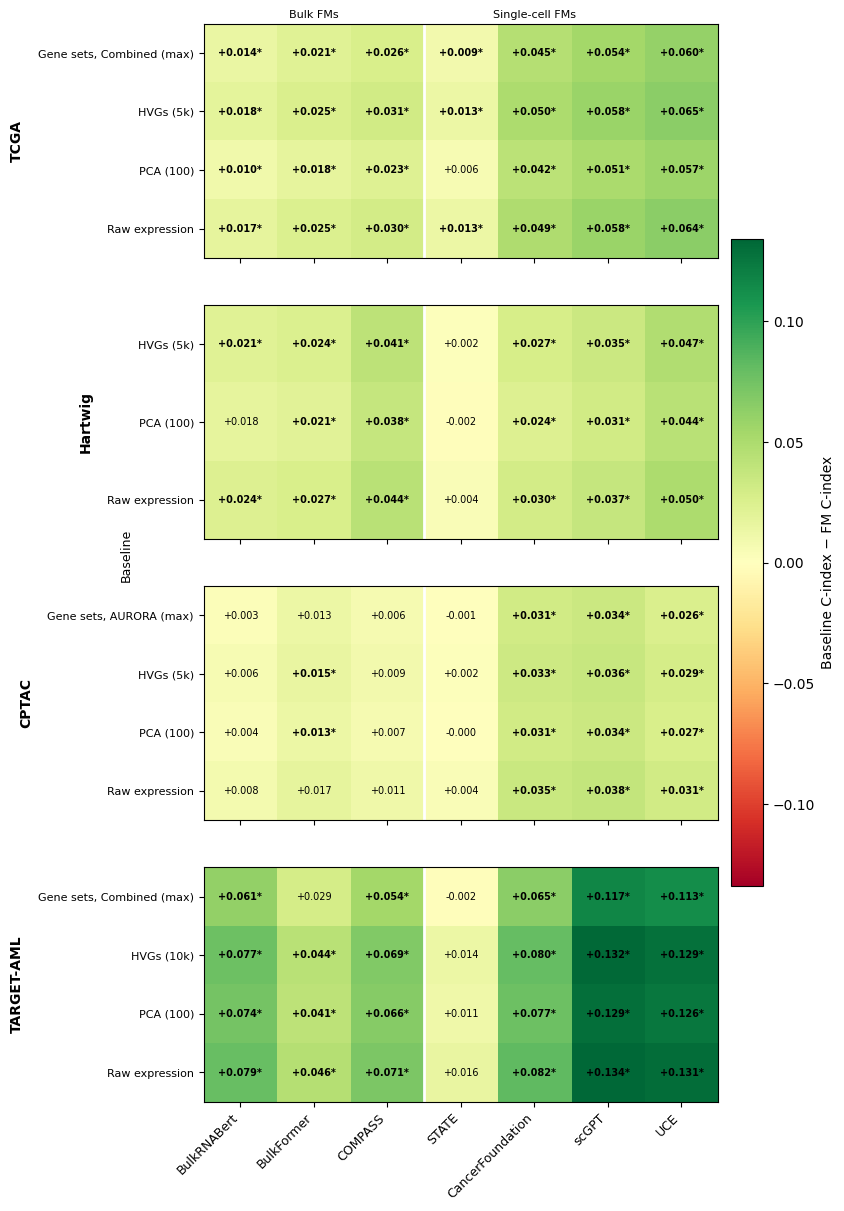

In [69]:
df = pd.read_csv(OUT_DIR / "stats" / "permutation_test_results.csv")
df["baseline_nHVGs"] = df["baseline_nHVGs"].fillna("None").astype(str)

def make_baseline_label(row):
    b, n = row["baseline"], row["baseline_nHVGs"]
    if b == "max_combined":    return "Gene sets, Combined (max)"
    if b == "max_AURORA":      return "Gene sets, AURORA (max)"
    if b == "RNA_seq" and n == "10000.0": return "HVGs (10k)"
    if b == "RNA_seq" and n == "5000.0":  return "HVGs (5k)"
    if b == "RNA_seq" and n == "1250.0":  return "HVGs (1250)"
    if b == "PCA_100":                return "PCA (100)"
    if b == "PCA_50":                 return "PCA (50)"
    if b == "RNA_seq" and n == "None":    return "Raw expression"
    return None

df["baseline_label"] = df.apply(make_baseline_label, axis=1)
df = df[df["baseline_label"].notna()]

# Verify labels present
print(df["baseline_label"].unique())

fixed_row_order = [
    "Gene sets, Combined (max)",
    "Gene sets, AURORA (max)",
    "HVGs (10k)",
    "HVGs (5k)",
    "HVGs (1250)",
    "PCA (100)",
    "PCA (50)",
    "Raw expression",
]

fm_order = ["BulkRNABert", "BulkFormer", "COMPASS", "STATE", "CancerFoundation", "scGPT", "UCE"]

vmax = df["mean_diff"].abs().max()

fig, axes = plt.subplots(4, 1, figsize=(8, 14), sharex=True)

for ax, dataset in zip(axes, DATASETS):
    sub = df[df["dataset"] == dataset].copy()
    rows = [r for r in fixed_row_order if r in sub["baseline_label"].values]

    pivot_diff = sub.pivot(index="baseline_label", columns="fm", values="mean_diff").reindex(
        index=rows, columns=fm_order)
    pivot_sig = sub.pivot(index="baseline_label", columns="fm", values="significant").reindex(
        index=rows, columns=fm_order)

    im = ax.imshow(pivot_diff.values, cmap="RdYlGn", vmin=-vmax, vmax=vmax, aspect="auto")

    for i in range(len(rows)):
        for j in range(len(fm_order)):
            val = pivot_diff.values[i, j]
            sig = pivot_sig.values[i, j]
            if pd.isna(val):
                continue
            weight = "bold" if sig else "normal"
            star = "*" if sig else ""
            ax.text(j, i, f"{val:+.3f}{star}", ha="center", va="center",
                    fontsize=7, fontweight=weight, color="black")

    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels(rows, fontsize=8)
    ax.set_ylabel(dataset_labels.get(dataset, dataset), fontsize=10, fontweight="bold", labelpad=10)
    ax.axvline(2.5, color="white", linewidth=2)

axes[-1].set_xticks(range(len(fm_order)))
axes[-1].set_xticklabels(fm_order, rotation=45, ha="right", fontsize=9)
axes[0].text(1, -0.6, "Bulk FMs", ha="center", fontsize=8, color="black", transform=axes[0].transData)
axes[0].text(4, -0.6, "Single-cell FMs", ha="center", fontsize=8, color="black", transform=axes[0].transData)

plt.colorbar(im, ax=axes, label="Baseline C-index − FM C-index", shrink=0.6, pad=0.02)
fig.text(0.02, 0.5, "Baseline", va="center", rotation="vertical", fontsize=9)

plt.savefig(FIGURE_DIR / "supp_permutation_heatmap.png", bbox_inches="tight")
plt.show()

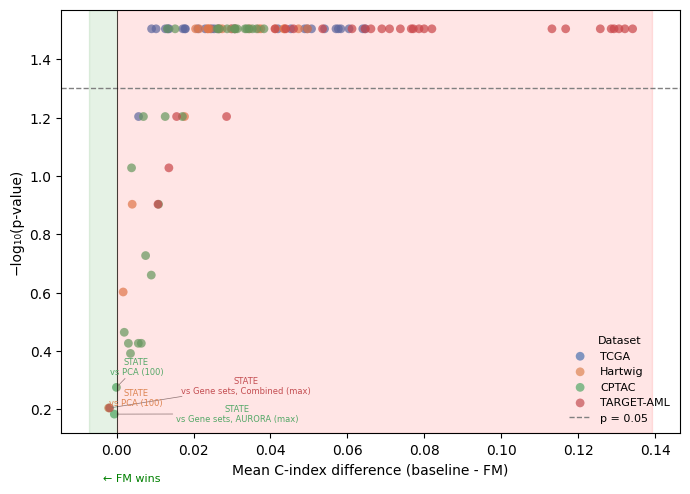

In [70]:
df = pd.read_csv(OUT_DIR / "stats" / "permutation_test_results.csv")
df["baseline_nHVGs"] = df["baseline_nHVGs"].fillna("None").astype(str)
df["baseline_label"] = df.apply(make_baseline_label, axis=1)
df = df[df["baseline_label"].notna()]

df["neg_log10_p"] = -np.log10(df["p_value"])

fig, ax = plt.subplots(figsize=(7, 5))

for dataset in DATASETS:
    group = df[df["dataset"] == dataset]
    ax.scatter(
        group["mean_diff"],
        group["neg_log10_p"],
        color=dataset_colors[dataset],
        label=dataset_labels.get(dataset, dataset),
        alpha=0.7,
        s=40,
        edgecolors="none",
    )

# Annotate FM-winning points (mean_diff < 0)
texts = []
fm_wins = df[df["mean_diff"] < 0]
for _, row in fm_wins.iterrows():
    texts.append(ax.text(
        row["mean_diff"], row["neg_log10_p"],
        f"{row['fm']}\nvs {row['baseline_label']}",
        fontsize=6, color=dataset_colors[row["dataset"]],
    ))
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))

# Significance threshold line
sig_threshold = -np.log10(0.05)
ax.axhline(sig_threshold, color="gray", linestyle="--", linewidth=1, label="p = 0.05")
ax.axvline(0, color="black", linestyle="-", linewidth=0.5)

# Shade region where FM wins
ax.axvspan(df["mean_diff"].min() - 0.005, 0, alpha=0.1, color="green")
ax.axvspan(0, df["mean_diff"].max() + 0.005, alpha=0.1, color="red")

ax.text(df["mean_diff"].min() * 0.3 - .003, -.05, "← FM wins", fontsize=8, color="green")

ax.set_xlabel("Mean C-index difference (baseline - FM)", fontsize=10)
ax.set_ylabel("−log₁₀(p-value)", fontsize=10)

ax.legend(title="Dataset", fontsize=8, title_fontsize=8, frameon=False)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "supp_pvalue_volcano.png", bbox_inches="tight")
plt.show()

### Extended Results

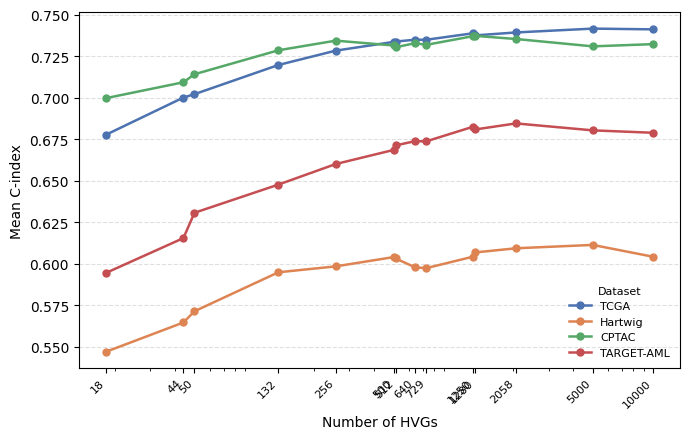

In [71]:
# --- HVG line chart ---
HVG_VALUES = [18, 44, 50, 132, 256, 500, 512, 640, 729, 1250, 1280, 2058, 5000, 10000]

hvg_rows = []
for d in DATASETS:
    df_agg = pd.read_csv(OUT_DIR / "transcriptomic" / f"{d}_survival_PFS_agg_filtered.csv")
    df_agg["nHVGs"] = df_agg["nHVGs"].fillna("None").astype(str)
    df_agg["overall_mean"] = pd.to_numeric(df_agg["overall_mean"], errors="coerce")

    # Keep only HVG rows (RNA_seq with numeric nHVGs)
    sub = df_agg[
        (df_agg["RNA_key"] == "RNA_seq") &
        (df_agg["nHVGs"] != "None")
    ].copy()
    sub["nHVGs_num"] = pd.to_numeric(sub["nHVGs"], errors="coerce")
    sub = sub.dropna(subset=["nHVGs_num", "overall_mean"])

    best = sub[["nHVGs_num", "overall_mean"]].copy()
    best["dataset"] = d

    hvg_rows.append(best)

hvg_df = pd.concat(hvg_rows, ignore_index=True)

fig, ax = plt.subplots(figsize=(7, 4.5))
for d in DATASETS:
    sub = hvg_df[hvg_df["dataset"] == d].sort_values("nHVGs_num")
    ax.plot(
        sub["nHVGs_num"], sub["overall_mean"],
        marker="o", label=dataset_labels.get(d, d),
        color=dataset_colors[d], linewidth=1.8, markersize=5,
    )

ax.set_xscale("log")
ax.set_xticks(HVG_VALUES)
ax.set_xticklabels(HVG_VALUES, rotation=45, ha="right", fontsize=8)
ax.set_xlabel("Number of HVGs", fontsize=10)
ax.set_ylabel("Mean C-index", fontsize=10)
ax.legend(title="Dataset", fontsize=8, title_fontsize=8, frameon=False)
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "hvg_line_chart.png", bbox_inches="tight")
plt.show()

### Summary Results

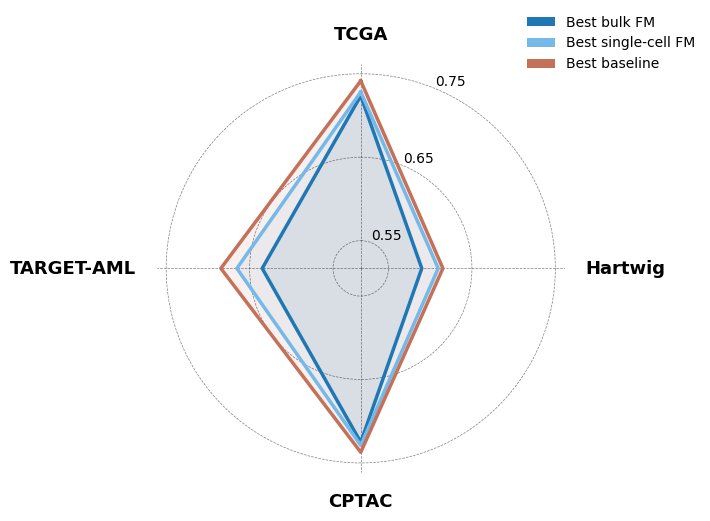

In [72]:
FM_KEYS_ORDERED = ['BulkFormer', 'BulkRNABert', 'COMPASS', 'CancerFoundation', 'STATE', 'scGPT', 'UCE']
BASELINE_CATS   = ['GS', 'HVG', 'PCA', 'Raw_expression']
BASELINE_LABELS = {'GS': 'Gene sets', 'HVG': 'HVGs', 'PCA': 'PCA', 'Raw_expression': 'Raw expression'}
FM_DISPLAY      = {'STATE': 'STATE-SE'}

# define group keys before they're used
BULK_FM_KEYS  = [FM_DISPLAY.get(k, k) for k in FM_KEYS_ORDERED[:3]]
SC_FM_KEYS    = [FM_DISPLAY.get(k, k) for k in FM_KEYS_ORDERED[3:]]
BASELINE_KEYS = list(BASELINE_LABELS.values())

def get_best_per_model(dataset):
    sub = df_all[df_all["dataset"] == dataset]
    out = {}
    for fm in FM_KEYS_ORDERED:
        rows = sub[sub["RNA_key"] == fm]
        out[FM_DISPLAY.get(fm, fm)] = rows["overall_mean"].max() if not rows.empty else np.nan
    for cat in BASELINE_CATS:
        rows = sub[sub["category"] == cat]
        out[BASELINE_LABELS[cat]] = rows["overall_mean"].max() if not rows.empty else np.nan
    return out

# use the global DATASETS (cell 2) — "TARGET_AML" with underscore matches df_all
all_models_data = {}
for dataset in DATASETS:
    for model, val in get_best_per_model(dataset).items():
        all_models_data.setdefault(model, {})[dataset] = val

group_best = {
    'Bulk FMs':        {d: np.nanmax([all_models_data.get(m, {}).get(d, np.nan) for m in BULK_FM_KEYS])  for d in DATASETS},
    'Single-cell FMs': {d: np.nanmax([all_models_data.get(m, {}).get(d, np.nan) for m in SC_FM_KEYS])    for d in DATASETS},
    'Baselines':       {d: np.nanmax([all_models_data.get(m, {}).get(d, np.nan) for m in BASELINE_KEYS]) for d in DATASETS},
}
GROUP_COLORS = {'Bulk FMs': '#1F78B4', 'Single-cell FMs': '#74B9E7', 'Baselines': '#C4715A'}

# ── radar ─────────────────────────────────────────────────────────────────────
N      = len(DATASETS)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
ax.set_theta_offset(np.pi / 2)    # TCGA at top
ax.set_theta_direction(-1)         # clockwise

for label, vals_dict in group_best.items():
    vals = [vals_dict.get(d, np.nan) for d in DATASETS]
    ax.plot(angles, vals + vals[:1], color=GROUP_COLORS[label], linewidth=2.5)
    ax.fill(angles, vals + vals[:1], color=GROUP_COLORS[label], alpha=0.10)

ax.set_thetagrids(np.degrees(angles[:-1]), labels=[''] * N)

all_vals = [v for m in all_models_data.values() for v in m.values() if not np.isnan(v)]
rmin = max(0.45, np.min(all_vals) - 0.03)
rmax = np.max(all_vals) + 0.02
ax.set_ylim(rmin, rmax)

# spoke labels — ha/va from spoke direction so text is centered on each radius
r_label = rmax + (rmax - rmin) * 0.10
for dataset, angle in zip(DATASETS, angles[:-1]):
    display = dataset_labels.get(dataset, dataset)
    disp_angle = np.pi / 2 - angle
    cos_a, sin_a = np.cos(disp_angle), np.sin(disp_angle)
    ha = 'center' if abs(cos_a) < 0.5 else ('left' if cos_a > 0 else 'right')
    va = 'center' if abs(sin_a) < 0.5 else ('bottom' if sin_a > 0 else 'top')
    ax.text(angle, r_label, display, ha=ha, va=va, fontsize=13, fontweight='bold')

rticks = np.array([0.55, 0.65, 0.75])
rticks = rticks[(rticks >= rmin) & (rticks <= rmax)]
ax.set_yticks(rticks)
ax.set_yticklabels([f"{v:.2f}" for v in rticks], fontsize=10)
ax.set_rlabel_position(22.5)
ax.grid(color='black', linestyle='--', linewidth=0.5, alpha=0.5)
ax.spines['polar'].set_visible(False)

legend_handles = [
    mpatches.Patch(facecolor='#1F78B4', label='Best bulk FM'),
    mpatches.Patch(facecolor='#74B9E7', label='Best single-cell FM'),
    mpatches.Patch(facecolor='#C4715A', label='Best baseline'),
]
ax.legend(handles=legend_handles, loc='upper right',
          bbox_to_anchor=(1.35, 1.15), fontsize=10, frameon=False)

plt.tight_layout()
plt.savefig(FIGURE_DIR / 'all_datasets_results_radar.png', dpi=300, bbox_inches='tight')
plt.show()

### Compare FMs with Similar Baselines

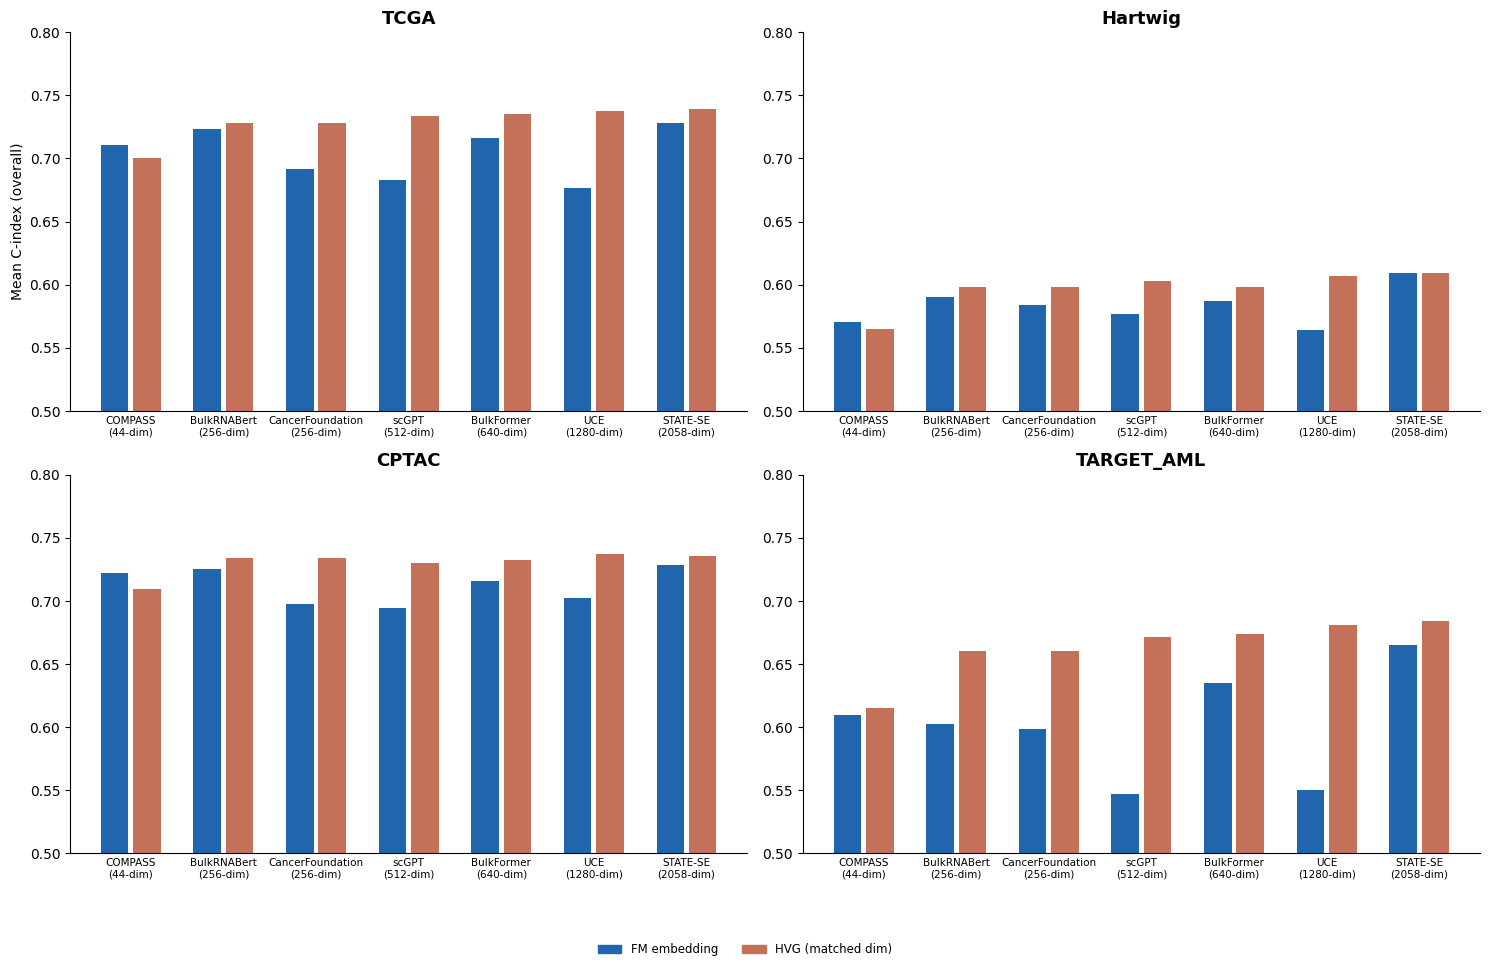

In [95]:
# ─────────────────────────────────────────────────────────────────────────────
# FM → baseline with matching dimensionality (nHVGs = FM embedding dim)
# ─────────────────────────────────────────────────────────────────────────────
FM_DIM = {
    "BulkRNABert":       256,
    "BulkFormer":        640,
    "COMPASS":            44,
    "scGPT":             512,
    "STATE":            2058,
    "CancerFoundation":  256,
    "UCE":              1280,
}
FM_BASELINE_MAP = {
    fm: [("RNA_seq", "RNA_seq", dim)] for fm, dim in FM_DIM.items()
}
FM_ORDER = ["COMPASS", "BulkRNABert", "CancerFoundation", "scGPT", "BulkFormer", "UCE", "STATE"]
FM_LABEL = {
    "BulkRNABert":      "BulkRNABert\n(256-dim)",
    "BulkFormer":       "BulkFormer\n(640-dim)",
    "COMPASS":          "COMPASS\n(44-dim)",
    "scGPT":            "scGPT\n(512-dim)",
    "STATE":            "STATE-SE\n(2058-dim)",
    "CancerFoundation": "CancerFoundation\n(256-dim)",
    "UCE":              "UCE\n(1280-dim)",
}
BL_COLOR_MAP = {
    "RNA_seq": "#C4715A",
}
FM_COLOR = "#2166ac"


def _best_row(df, rna_key, nHVGs=None):
    """Return the row with the highest overall_mean for a given (rna_key, nHVGs)."""
    df = df.copy()
    df["overall_mean"] = pd.to_numeric(df["overall_mean"], errors="coerce")
    df["nHVGs"]        = pd.to_numeric(df["nHVGs"],        errors="coerce")
    if nHVGs is None:
        mask = (df["RNA_key"] == rna_key) & df["nHVGs"].isna()
    else:
        mask = (df["RNA_key"] == rna_key) & (df["nHVGs"] == nHVGs)
    sub = df[mask].dropna(subset=["overall_mean"])
    return sub.loc[sub["overall_mean"].idxmax()] if not sub.empty else None


fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharey=False)
axes_flat = axes.flatten()

legend_items = {}

for ax, d in zip(axes_flat, DATASETS):
    df_agg = pd.read_csv(OUT_DIR / "transcriptomic" / f"{d}_survival_PFS_agg_filtered.csv")

    x = 0
    tick_pos, tick_lbl = [], []

    for fm in FM_ORDER:
        baselines = FM_BASELINE_MAP[fm]
        n_bars = 1 + len(baselines)
        bw     = 0.7 / n_bars
        offs   = np.arange(n_bars) * bw - (n_bars - 1) * bw / 2

        fm_row = _best_row(df_agg, fm)
        if fm_row is None:
            x += 1
            continue

        # FM bar
        ax.bar(x + offs[0], fm_row["overall_mean"], width=bw * 0.85,
               color=FM_COLOR, capsize=2.5,
               error_kw={"linewidth": 0.8, "ecolor": "#555"})
        legend_items.setdefault("FM embedding",
                                mpatches.Patch(color=FM_COLOR, label="FM embedding"))

        # Baseline bar (RNA_seq with matching nHVGs)
        for j, (bl_lbl, rk, nhvg) in enumerate(baselines):
            color  = BL_COLOR_MAP[bl_lbl]
            bl_row = _best_row(df_agg, rk, nhvg)
            if bl_row is not None:
                ax.bar(x + offs[j + 1], bl_row["overall_mean"], width=bw * 0.85,
                       color=color, capsize=2.5,
                       error_kw={"linewidth": 0.8, "ecolor": "#555"})
            legend_items.setdefault(f"HVG (matched dim)",
                                    mpatches.Patch(color=color, label="HVG (matched dim)"))

        tick_pos.append(x)
        tick_lbl.append(FM_LABEL.get(fm, fm))
        x += 1

    ax.set_xticks(tick_pos)
    ax.set_xticklabels(tick_lbl, fontsize=7.5)
    ax.set_ylim(0.50, 0.80)
    ax.set_title(d, fontsize=13, fontweight="bold")
    if d == DATASETS[0]:
        ax.set_ylabel("Mean C-index (overall)")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="x", length=0)

fig.legend(
    handles=list(legend_items.values()),
    loc="lower center",
    ncol=len(legend_items),
    fontsize=8.5,
    bbox_to_anchor=(0.5, -0.08),
    frameon=False,
)
#fig.suptitle("FM embeddings vs. HVG baseline with matched dimensionality", fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "fm_vs_matched_dim_baselines.png", bbox_inches="tight")
plt.show()

### Linear Probe

In [74]:
lp = pd.read_csv(REPO_DIR / "benchmarking_results" / "linear_probe" / "linear_probing_results.csv")

# Readable label for each embedding spec
def emb_label(rna_key, n_hvgs):
    if rna_key == "RNA_seq":
        return f"RNA_seq_full" if pd.isna(n_hvgs) else f"RNA_seq_{int(n_hvgs)}"
    return rna_key

lp["emb"] = lp.apply(lambda r: emb_label(r["rna_key"], r["n_hvgs"]), axis=1)

# Average metrics over 5 splits
group_cols = ["dataset", "emb", "rna_key", "n_hvgs", "task"]
lp_agg = (
    lp.groupby(group_cols, dropna=False)   # <-- add this
    .agg(
        accuracy_mean        = ("accuracy",       "mean"),
        accuracy_std         = ("accuracy",       "std"),
        macro_f1_mean        = ("macro_f1",       "mean"),
        macro_f1_std         = ("macro_f1",       "std"),
        kappa_mean           = ("kappa", "mean"),
        kappa_std            = ("kappa", "std"),
        n_splits             = ("accuracy",       "count"),
    )
    .reset_index()
)

print(f"Loaded {len(lp)} rows → {len(lp_agg)} aggregated (dataset × emb × task)")
lp_agg.head(10)

Loaded 1280 rows → 256 aggregated (dataset × emb × task)


,dataset,emb,rna_key,n_hvgs,task,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,kappa_mean,kappa_std,n_splits
0,CPTAC,BulkFormer,BulkFormer,NaN,cancer_type,0.918383,0.016345,0.539723,0.067078,NaN,NaN,5
1,CPTAC,BulkFormer,BulkFormer,NaN,grade,0.707179,0.018175,0.453838,0.037168,0.028243,0.030789,5
2,CPTAC,BulkFormer,BulkFormer,NaN,organ,0.917308,0.018152,0.538012,0.065653,NaN,NaN,5
3,CPTAC,BulkRNABert,BulkRNABert,NaN,cancer_type,0.878124,0.003173,0.497051,0.022950,NaN,NaN,5
4,CPTAC,BulkRNABert,BulkRNABert,NaN,grade,0.718826,0.023915,0.461118,0.082893,0.053926,0.109171,5
5,CPTAC,BulkRNABert,BulkRNABert,NaN,organ,0.879211,0.009018,0.464810,0.050110,NaN,NaN,5
6,CPTAC,COMPASS,COMPASS,NaN,cancer_type,0.953846,0.015316,0.956416,0.015215,NaN,NaN,5
7,CPTAC,COMPASS,COMPASS,NaN,grade,0.702855,0.028220,0.464109,0.056110,0.057631,0.068772,5
8,CPTAC,COMPASS,COMPASS,NaN,organ,0.952663,0.014494,0.955363,0.013691,NaN,NaN,5
9,CPTAC,CancerFoundation,CancerFoundation,NaN,cancer_type,0.737782,0.022544,0.337828,0.022793,NaN,NaN,5


In [75]:
EMB_ORDER = [
    "BulkFormer", "BulkRNABert", "COMPASS",
    "scGPT", "STATE", "CancerFoundation", "UCE",
    "ssGSEA_AURORA", "ssGSEA_immuno", "ssGSEA_hallmark", "ssGSEA_combined",
    "max_AURORA", "max_immuno", "max_hallmark", "max_combined",
    "PCA_50", "PCA_100",
    "RNA_seq_18", "RNA_seq_44", "RNA_seq_50", "RNA_seq_132", "RNA_seq_256", "RNA_seq_500",
    "RNA_seq_512", "RNA_seq_640", "RNA_seq_729", "RNA_seq_1250", "RNA_seq_1280",
    "RNA_seq_2058", "RNA_seq_5000", "RNA_seq_10000", "RNA_seq_full",
]

LP_DATASETS = ["TCGA", "CPTAC", "Hartwig"]  # TARGET_AML had no applicable tasks
TASKS       = ["organ", "grade"]   # primary tumor site, tumor grade
TASK_METRIC = {"cancer_type": "macro_f1", "grade": "kappa", "organ": "macro_f1"}
TASK_LABEL  = {"cancer_type": "Cancer type\n(macro F1)",
               "grade":       "Tumor grade\n(Cohen's κ)",
               "organ":       "Primary tumor site\n(macro F1)"}

# Display names used in figures
def display_name(emb):
    if emb == "STATE":
        return "STATE-SE"
    if emb == "RNA_seq_full":
        return "Raw expression"
    if emb.startswith("RNA_seq_"):
        return f"HVG ({int(emb.split('_')[-1]):,})"
    return emb


In [76]:
rows = []
for task in TASKS:
    metric = TASK_METRIC[task] + "_mean"
    sub = lp_agg[lp_agg["task"] == task]
    for dataset in LP_DATASETS:
        dsub = sub[sub["dataset"] == dataset]
        if dsub.empty:
            continue
        best = dsub.loc[dsub[metric].idxmax()]
        rows.append({
            "task": task, "dataset": dataset,
            "best_emb": best["emb"],
            "mean": best[metric],
            "std":  best[TASK_METRIC[task] + "_std"],
        })

summary = pd.DataFrame(rows)
print(summary.to_string(index=False))

 task dataset      best_emb     mean      std
organ    TCGA  RNA_seq_5000 0.961746 0.005287
organ   CPTAC       COMPASS 0.955363 0.013691
organ Hartwig  RNA_seq_5000 0.484237 0.045882
grade    TCGA  RNA_seq_5000 0.506756 0.023902
grade   CPTAC RNA_seq_10000 0.381399 0.079650


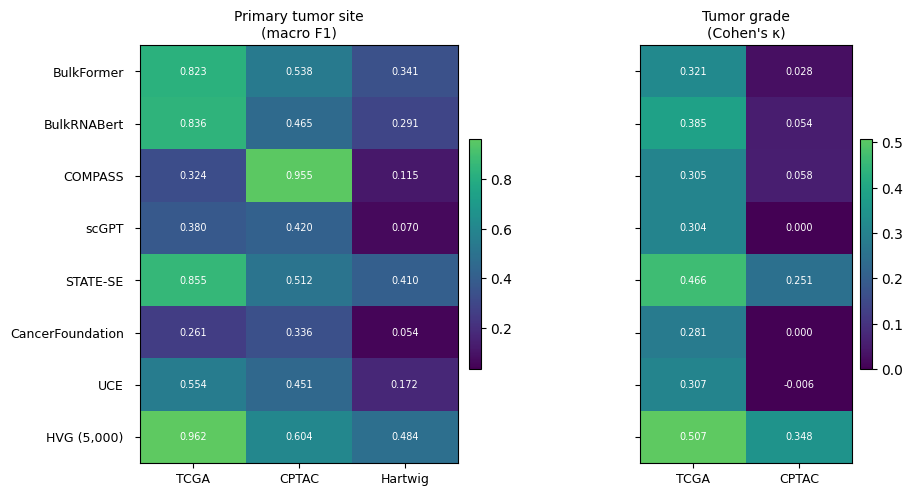

In [77]:
TASKS_TO_PLOT = ["organ", "grade"]
TASK_DATASETS = {
    "organ": ["TCGA", "CPTAC", "Hartwig"],
    "grade": ["TCGA", "CPTAC"],
}

included_embs = [
    "BulkFormer",
    "BulkRNABert",
    "COMPASS",
    "scGPT",
    "STATE",
    "CancerFoundation",
    "UCE",
    "RNA_seq_5000",
    #"RNA_seq_full",
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 5.5),
    sharey=True,
    gridspec_kw={"width_ratios": [3, 2]}
)

axes = np.atleast_1d(axes)

for ax, task in zip(axes, TASKS_TO_PLOT):
    metric = TASK_METRIC[task] + "_mean"
    datasets_for_task = TASK_DATASETS[task]

    sub = lp_agg[
        (lp_agg["task"] == task) &
        (lp_agg["emb"].isin(included_embs)) &
        (lp_agg["dataset"].isin(datasets_for_task))
    ].copy()

    mat = (
        sub.pivot(index="emb", columns="dataset", values=metric)
        .reindex(index=included_embs, columns=datasets_for_task)
    )

    vals = mat.to_numpy(dtype=float)
    finite_vals = vals[np.isfinite(vals)]
    vmin = max(finite_vals.min() - 0.02, 0) if finite_vals.size else 0
    vmax = finite_vals.max() if finite_vals.size else 1

    colors = plt.cm.viridis(np.linspace(0.0, 0.75, 256))
    cmap = mcolors.LinearSegmentedColormap.from_list("viridis_dark", colors)

    im = ax.imshow(vals, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")

    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            val = mat.iloc[i, j]
            if pd.notna(val):
                ax.text(
                    j, i, f"{val:.3f}",
                    ha="center", va="center",
                    fontsize=7, color="white"
                )

    ax.set_title(TASK_LABEL[task], fontsize=10)
    ax.set_xticks(range(len(datasets_for_task)))
    ax.set_xticklabels(datasets_for_task, fontsize=9)
    ax.set_yticks(range(len(included_embs)))

# Set y-axis labels only once, after the loop
axes[0].set_yticklabels([display_name(e) for e in included_embs], fontsize=9)
axes[0].tick_params(axis="y", pad=8)

# Hide y tick labels on the second subplot without modifying the shared axis labels
axes[1].tick_params(axis="y", labelleft=False)

for ax in axes:
    fig.colorbar(ax.images[0], ax=ax, shrink=0.55, pad=0.03)

fig.subplots_adjust(left=0.28, right=0.97, top=0.88, bottom=0.12, wspace=0.35)
#fig.suptitle("Linear probing: mean metric across 5 splits", fontsize=13)

plt.savefig(FIGURE_DIR / "linear_probing_heatmap_site_grade.png", dpi=300)
plt.show()

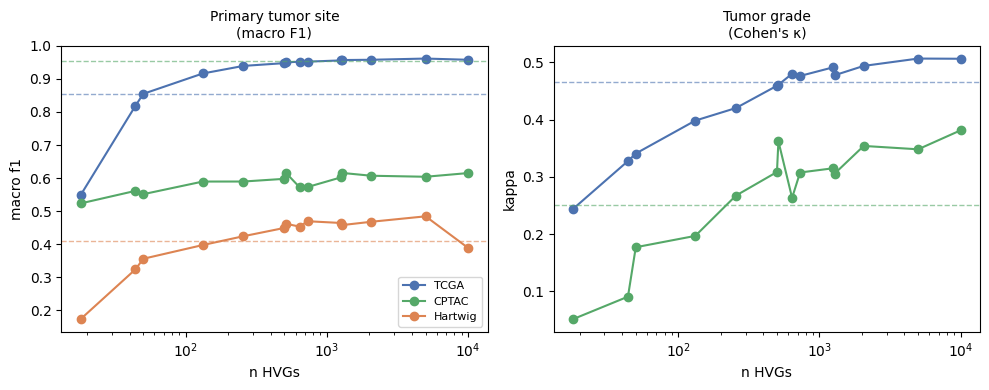

In [78]:
# Useful for seeing how much information scales with HVG count
fig, axes = plt.subplots(1, len(TASKS), figsize=(10, 4), sharey=False)

hvg_counts = [18, 44, 50, 132, 256, 500, 512, 640, 729, 1250, 1280, 2058, 5000, 10000]
hvg_embs   = [f"RNA_seq_{n}" for n in hvg_counts]

for ax, task in zip(axes, TASKS):
    metric = TASK_METRIC[task] + "_mean"
    sub = lp_agg[lp_agg["task"] == task]

    for dataset in LP_DATASETS:
        dsub = sub[sub["dataset"] == dataset].set_index("emb")

        # HVG sweep line
        hvg_vals = [dsub.loc[e, metric] if e in dsub.index else np.nan for e in hvg_embs]
        ax.plot(hvg_counts, hvg_vals, marker="o", label=dataset,
                color=dataset_colors[dataset])

        # FM best as horizontal dashed line
        fm_best = dsub.loc[dsub.index.isin(FM_ALL), metric].max() if any(e in dsub.index for e in FM_ALL) else np.nan
        ax.axhline(fm_best, color=dataset_colors[dataset], linestyle="--", linewidth=1, alpha=0.6)

    ax.set_xscale("log")
    ax.set_xlabel("n HVGs")
    ax.set_title(TASK_LABEL[task], fontsize=10)
    ax.set_ylabel(TASK_METRIC[task].replace("_", " "))
    if ax is axes[0]:
        ax.legend(fontsize=8)

#fig.suptitle("HVG sweep vs best FM (dashed) — linear probe", fontsize=12)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "linear_probing_hvg_sweep.png", dpi=300, bbox_inches="tight")
plt.show()


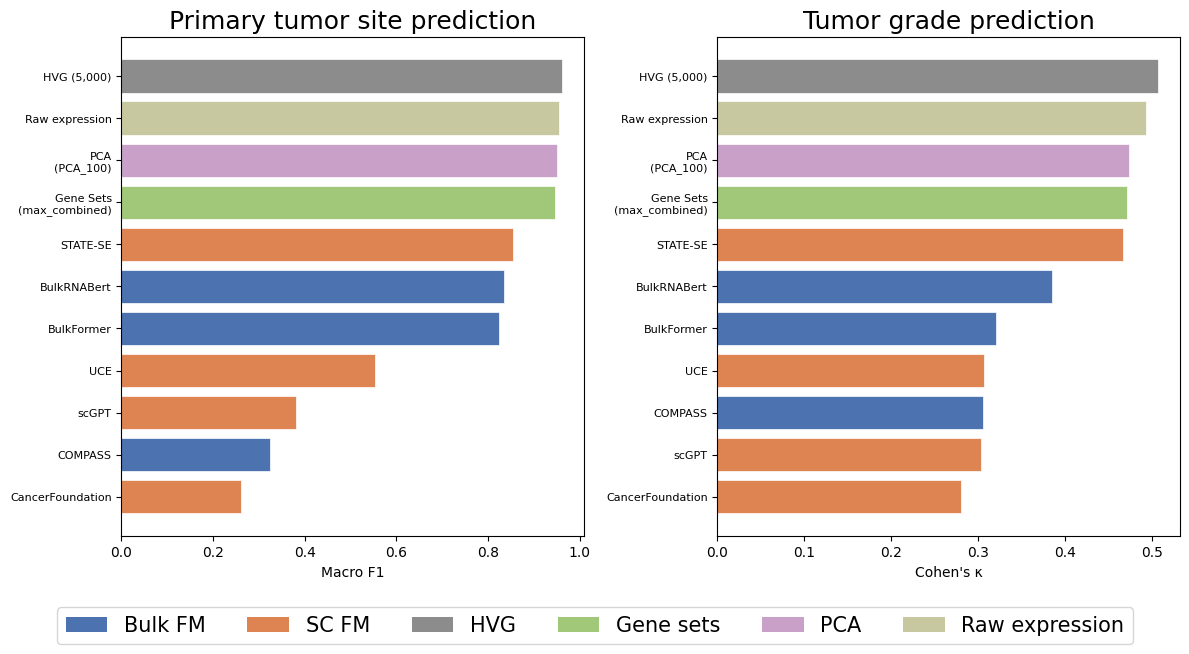

In [79]:
BASELINE_GROUPS = {
    "HVG":            [e for e in EMB_ORDER if e.startswith("RNA_seq_") and e != "RNA_seq_full"],
    "Gene Sets":      [e for e in EMB_ORDER if e.startswith("ssGSEA_") or e.startswith("max_")],
    "PCA":            [e for e in EMB_ORDER if e.startswith("PCA_")],
    "Raw expression": ["RNA_seq_full"],
}

BAR_COLORS = {
    "BulkFormer":       "#4C72B0",
    "BulkRNABert":      "#4C72B0",
    "COMPASS":          "#4C72B0",
    "scGPT":            "#DD8452",
    "STATE":            "#DD8452",
    "CancerFoundation": "#DD8452",
    "UCE":              "#DD8452",
    "HVG":              "#8C8C8C",
    "Gene Sets":        "#A0C878",
    "PCA":              "#C8A0C8",
    "Raw expression":   "#C8C8A0",
}

TASK_PRIMARY_METRIC = {
    "cancer_type": ("macro_f1_mean", "macro_f1_std", "Macro F1"),
    "grade":       ("kappa_mean", "kappa_std", "Cohen's κ"),
    "organ":       ("macro_f1_mean", "macro_f1_std", "Macro F1"),
}
TASK_TITLE = {
    "cancer_type": "Cancer type prediction",
    "grade":       "Tumor grade prediction",
    "organ":       "Primary tumor site prediction",
}

tcga = lp_agg[lp_agg["dataset"] == "TCGA"].set_index("emb")

fig, axes = plt.subplots(1, len(TASKS), figsize=(12, 6))

for ax, task in zip(axes, TASKS):
    mean_col, std_col, ylabel = TASK_PRIMARY_METRIC[task]
    sub = tcga[tcga["task"] == task]

    entries = []

    # One bar per FM
    for emb in ["BulkFormer", "BulkRNABert", "COMPASS", "scGPT", "STATE", "CancerFoundation", "UCE"]:
        if emb not in sub.index or not np.isfinite(sub.loc[emb, mean_col]):
            continue
        entries.append({
            "label": display_name(emb),
            "mean":  sub.loc[emb, mean_col],
            "std":   sub.loc[emb, std_col],
            "color": BAR_COLORS[emb],
        })

    # One bar per baseline group
    for group_label, group_embs in BASELINE_GROUPS.items():
        group_rows = sub.loc[sub.index.isin(group_embs), mean_col].dropna()
        if group_rows.empty:
            continue
        best_emb = group_rows.idxmax()
        # Show best embedding name beneath label, except for Raw expression
        if group_label == "Raw expression":
            display_label = group_label
        elif group_label == "HVG":
            display_label = display_name(best_emb)          # e.g. "HVG (5,000)"
        else:
            display_label = f"{group_label}\n({best_emb})"

        entries.append({
            "label": display_label,
            "mean":  sub.loc[best_emb, mean_col],
            "std":   sub.loc[best_emb, std_col],
            "color": BAR_COLORS[group_label],
        })

    entries = sorted(entries, key=lambda e: e["mean"], reverse=True)

    labels = [e["label"] for e in entries]
    means  = [e["mean"]  for e in entries]
    stds   = [e["std"]   for e in entries]
    colors = [e["color"] for e in entries]

    ax.barh(range(len(entries)), means,
            color=colors, edgecolor="white", linewidth=0.5,
            error_kw=dict(elinewidth=1, capsize=3, ecolor="black"))

    ax.set_yticks(range(len(entries)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel(ylabel, fontsize=10)
    ax.set_title(TASK_TITLE[task], fontsize=18)
    ax.axvline(0, color="black", linewidth=0.5)
    '''
    for i, (m, s) in enumerate(zip(means, stds)):
        ax.text(m + s + 0.005, i, f"{m:.3f}", va="center", fontsize=7)
    '''
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#4C72B0", label="Bulk FM"),
    Patch(facecolor="#DD8452", label="SC FM"),
    Patch(facecolor="#8C8C8C", label="HVG"),
    Patch(facecolor="#A0C878", label="Gene sets"),
    Patch(facecolor="#C8A0C8", label="PCA"),
    Patch(facecolor="#C8C8A0", label="Raw expression"),
]
fig.legend(handles=legend_elements, loc="lower center", ncol=6,
           fontsize=15, bbox_to_anchor=(0.5, -0.1))

plt.tight_layout()
plt.savefig(FIGURE_DIR / "linear_probing_tcga_bars.png", dpi=300, bbox_inches="tight")
plt.show()

### UMAP Visualizations

In [80]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import Normalize
import umap
from sklearn.preprocessing import StandardScaler

BASE = "/data/rbg/users/ashyamal/RNA-FM-benchmarking"

with open(f"{BASE}/data/RNA_embeddings/TCGA_processed_cleaned.pkl", "rb") as f:
    data = pickle.load(f)

In [81]:
BAD_VALUES = {"unknown", "not reported", "'--", "not applicable", "n/a", "na",
              "none", "", "nan/null", "--"}

def clean_val(x):
    if pd.isnull(x): return np.nan
    return np.nan if str(x).strip().lower() in BAD_VALUES else x

# Same one-row-per-patient rule as mech/linear_probing.py and
# train/train_simple_clinical_baseline.py: diagnosis fields come from the
# primary-disease diagnosis only; other fields are the first non-null value.
def dedup_gdc_clinical(clinical, id_col):
    out = clinical.groupby(id_col).first()
    flag = "diagnoses.diagnosis_is_primary_disease"
    if flag in clinical.columns:
        diag_cols = [c for c in clinical.columns if c.startswith("diagnoses.")]
        prim = clinical[clinical[flag].astype(str).str.strip().str.lower() == "true"].groupby(id_col)[diag_cols].first()
        out[diag_cols] = prim.reindex(out.index)
    return out

# Two-tier tumor grade, matching the linear probing task (GX/GB excluded)
GRADE_TWO_TIER = {
    "G1": "low",  "G2": "low",  "Low Grade":  "low",
    "G3": "high", "G4": "high", "High Grade": "high",
}
grade_order  = ["low", "high"]
grade_labels = {"low": "Low (G1–G2, Low Grade)", "high": "High (G3–G4, High Grade)"}
grade_colors = {"low": "#4575b4", "high": "#d73027"}

clinical = pd.read_csv(f"{REPO_DIR}/data/TCGA/clinical/clinical.tsv", sep="\t", dtype=str,
                       low_memory=False,
                       usecols=["cases.submitter_id", "diagnoses.tumor_grade",
                                "diagnoses.diagnosis_is_primary_disease"])

clinical = dedup_gdc_clinical(clinical.apply(lambda col: col.map(clean_val)), "cases.submitter_id")

pids = [p for p in data if data[p].get("PFS_time") is not None]

def get_val(pid, col):
    if pid not in clinical.index: return np.nan
    return clinical.loc[pid, col]

# The two linear probing annotations (TCGA definitions)
meta = pd.DataFrame({
    "organ": [data[p]["organ"] for p in pids],         # primary tumor site
    "grade": [GRADE_TWO_TIER.get(get_val(p, "diagnoses.tumor_grade"), np.nan) for p in pids],
}, index=pids)

print(f"Samples: {len(pids)}")
print(f"Grade:   {meta['grade'].notna().sum()} / {len(meta)}")
print(meta["grade"].value_counts())

Samples: 10388
Grade:   4284 / 10388
grade
high    2360
low     1924
Name: count, dtype: int64


In [82]:
EMBEDDING_CONFIGS = {
    "BulkFormer":  lambda r: np.asarray(r["BulkFormer"]).squeeze(),
    "BulkRNABert": lambda r: np.asarray(r["BulkRNABert"]).squeeze(),
    "STATE-SE":    lambda r: np.asarray(r["STATE"]).squeeze(),
    "HVG (5,000)": lambda r: np.asarray(r["RNA_seq"])[:5000],
}

umaps = {}
for name, getter in EMBEDDING_CONFIGS.items():
    X = np.stack([getter(data[p]) for p in pids]).astype(np.float32)
    X = StandardScaler().fit_transform(X)
    reducer = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.3,
                        random_state=42, low_memory=False, n_jobs=8)
    umaps[name] = reducer.fit_transform(X)
    print(f"  {name}: done  shape={umaps[name].shape}")

/data/rbg/users/ashyamal/miniconda3/envs/rna_modeling/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  BulkFormer: done  shape=(10388, 2)


/data/rbg/users/ashyamal/miniconda3/envs/rna_modeling/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  BulkRNABert: done  shape=(10388, 2)


/data/rbg/users/ashyamal/miniconda3/envs/rna_modeling/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  STATE-SE: done  shape=(10388, 2)


/data/rbg/users/ashyamal/miniconda3/envs/rna_modeling/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  HVG (5,000): done  shape=(10388, 2)


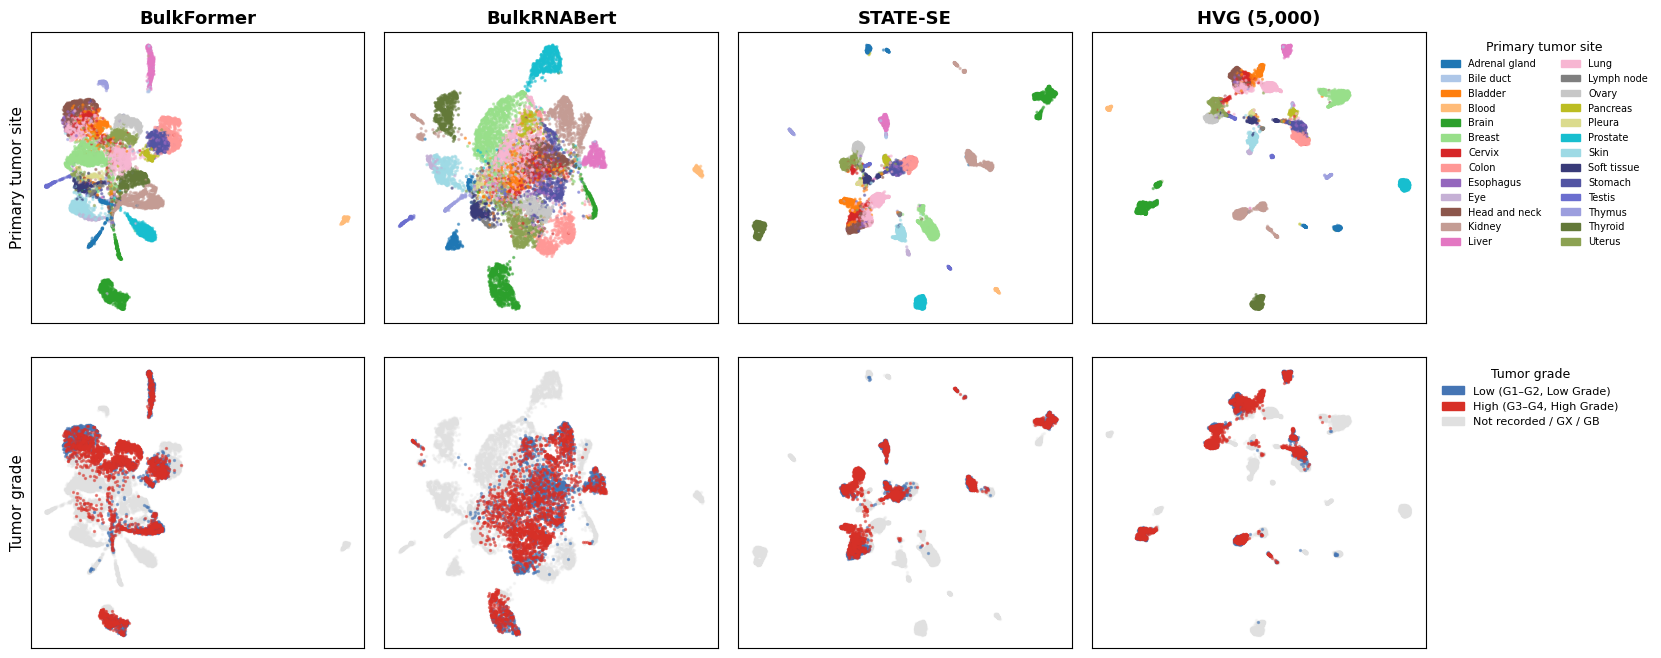

In [83]:
EMBED_NAMES = list(EMBEDDING_CONFIGS.keys())
n_models = len(EMBED_NAMES)
s, alpha = 2, 0.5

# ── palettes ──────────────────────────────────────────────────────────────────
all_colors    = list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors)
organ_cats    = sorted(meta["organ"].unique())
organ_palette = {c: all_colors[i % 40] for i, c in enumerate(organ_cats)}

row_labels = ["Primary tumor site", "Tumor grade"]

fig, axes = plt.subplots(2, n_models, figsize=(n_models * 4.5, 8),
                         gridspec_kw={"hspace": 0.12, "wspace": 0.06})

for col, name in enumerate(EMBED_NAMES):
    xy = umaps[name]
    axes[0, col].set_title(name, fontsize=13, fontweight="bold", pad=6)

    # ── row 0: primary tumor site ─────────────────────────────────────────────
    ax = axes[0, col]
    ax.scatter(xy[:, 0], xy[:, 1],
               c=[organ_palette[o] for o in meta["organ"]],
               s=s, alpha=alpha, rasterized=True)

    # ── row 1: tumor grade (two-tier) ─────────────────────────────────────────
    ax = axes[1, col]
    no_grade = meta["grade"].isna().values
    ax.scatter(xy[no_grade, 0], xy[no_grade, 1],
               c="#e0e0e0", s=s, alpha=0.25, rasterized=True)
    for g in grade_order:
        mask = (meta["grade"] == g).values
        ax.scatter(xy[mask, 0], xy[mask, 1],
                   c=grade_colors[g], s=s, alpha=alpha, rasterized=True)

    for row in range(2):
        axes[row, col].set_xticks([]); axes[row, col].set_yticks([])
        if col == 0: axes[row, col].set_ylabel(row_labels[row], fontsize=11)

# ── legends ───────────────────────────────────────────────────────────────────
# Primary tumor site legend
organ_handles = [mpatches.Patch(color=organ_palette[o], label=o) for o in organ_cats]
axes[0, -1].legend(handles=organ_handles, loc="upper left", bbox_to_anchor=(1.02, 1.0),
                   fontsize=7, ncol=2, frameon=False, title="Primary tumor site", title_fontsize=9)

# Tumor grade legend
grade_handles = ([mpatches.Patch(color=grade_colors[g], label=grade_labels[g]) for g in grade_order]
                 + [mpatches.Patch(color="#e0e0e0", label="Not recorded / GX / GB")])
axes[1, -1].legend(handles=grade_handles, loc="upper left", bbox_to_anchor=(1.02, 1.0),
                   fontsize=8, frameon=False, title="Tumor grade", title_fontsize=9)

plt.savefig(FIGURE_DIR / "TCGA_UMAP_clinical_features.png", dpi=150, bbox_inches="tight")
plt.show()


### Binning

In [84]:
# ── Binning ablation config ────────────────────────────────────────────────
# Fixed model config used in the binning experiment
BINNED_ARCH = "ResidualMLP"
BINNED_LOSS = "CIndex"
BINNED_SEED = 37

BEST_NHVGS = {"TCGA": 5000, "Hartwig": 10000, "CPTAC": 5000, "TARGET_AML": 5000}

N_BINS_ORDER = [2, 8, 16, 32, 51, 64, 128, 256, 512, 1024]

STRATEGY_STYLE = {
    "linear":              dict(color="#2ca02c", marker="o", ls="-",  label="Per-gene linear"),
    "quantile":            dict(color="#98df8a", marker="o", ls="-",  label="Per-gene quantile"),
    "global_linear":       dict(color="#1f77b4", marker="o", ls="-",  label="Global linear"),
    "global_quantile":     dict(color="#aec7e8", marker="o", ls="-",  label="Global quantile"),
    "per_sample_linear":   dict(color="#d62728", marker="o", ls="-",  label="Per-sample linear"),
    "per_sample_quantile": dict(color="#ff9896", marker="o", ls="-",  label="Per-sample quantile"),
}

In [85]:
# ── Load binned CSVs ───────────────────────────────────────────────────────
binned_dfs = []
for ds in DATASETS:
    path = Path(BASE) / "model_outputs" / ds / "survival" / "PFS" / "binned_HVG_ablation" / "binned_HVG_metrics.csv"
    df = pd.read_csv(path)
    df["dataset"] = ds
    binned_dfs.append(df)
binned = pd.concat(binned_dfs, ignore_index=True)
binned = binned[binned["error"].isna() | (binned["error"] == "")]

# Keep only the fixed config used in this experiment
binned = binned[
    (binned["arch"] == BINNED_ARCH) &
    (binned["loss"] == BINNED_LOSS) &
    (binned["seed"] == BINNED_SEED)
]
binned = binned[binned.apply(lambda r: r["n_hvgs"] == BEST_NHVGS[r["dataset"]], axis=1)]

# Average over splits
binned_agg = (
    binned
    .groupby(["dataset", "bin_strategy", "n_bins"])["overall"]
    .agg(mean="mean", std="std", n="count")
    .reset_index()
)

print(binned_agg.groupby(["dataset", "bin_strategy"])["n_bins"].count())
print(binned_agg.head(10).to_string(index=False))


dataset     bin_strategy       
CPTAC       global_linear          10
            global_quantile        10
            linear                 10
            per_sample_linear      10
            per_sample_quantile    10
            quantile               10
Hartwig     global_linear          10
            global_quantile        10
            linear                 10
            per_sample_linear      10
            per_sample_quantile    10
            quantile               10
TARGET_AML  global_linear          10
            global_quantile        10
            linear                 10
            per_sample_linear      10
            per_sample_quantile    10
            quantile               10
TCGA        global_linear          10
            global_quantile        10
            linear                 10
            per_sample_linear      10
            per_sample_quantile    10
            quantile               10
Name: n_bins, dtype: int64
dataset  bin_strategy  n_bins

In [86]:
# ── Continuous HVG baseline: best arch/loss per dataset ───────────────────
# Uses the val-selected agg CSVs from the main benchmarking experiment
hvg_dfs = []
for ds in DATASETS:
    df = pd.read_csv(OUT_DIR / "transcriptomic" / f"{ds}_survival_PFS_agg.csv")
    df["nHVGs"] = df["nHVGs"].fillna("None").astype(str)
    df["overall_mean"] = pd.to_numeric(df["overall_mean"], errors="coerce")
    hvg = df[
        (df["RNA_key"] == "RNA_seq") &
        (df["nHVGs"] == str(float(BEST_NHVGS[ds])))
    ].copy()
    hvg["dataset"] = ds
    hvg_dfs.append(hvg)

hvg_df = pd.concat(hvg_dfs, ignore_index=True)
hvg_filtered = hvg_df[(hvg_df["arch"] == BINNED_ARCH) & (hvg_df["loss"] == BINNED_LOSS)]
hvg_best = (
    hvg_filtered
    .loc[hvg_filtered.groupby("dataset")["overall_mean"].idxmax()]
    .set_index("dataset")
)
print(hvg_best[["arch", "loss", "overall_mean", "overall_std"]].to_string())


                   arch    loss  overall_mean  overall_std
dataset                                                   
CPTAC       ResidualMLP  CIndex      0.730861     0.033068
Hartwig     ResidualMLP  CIndex      0.613952     0.017106
TARGET_AML  ResidualMLP  CIndex      0.685309     0.008564
TCGA        ResidualMLP  CIndex      0.741543     0.010578


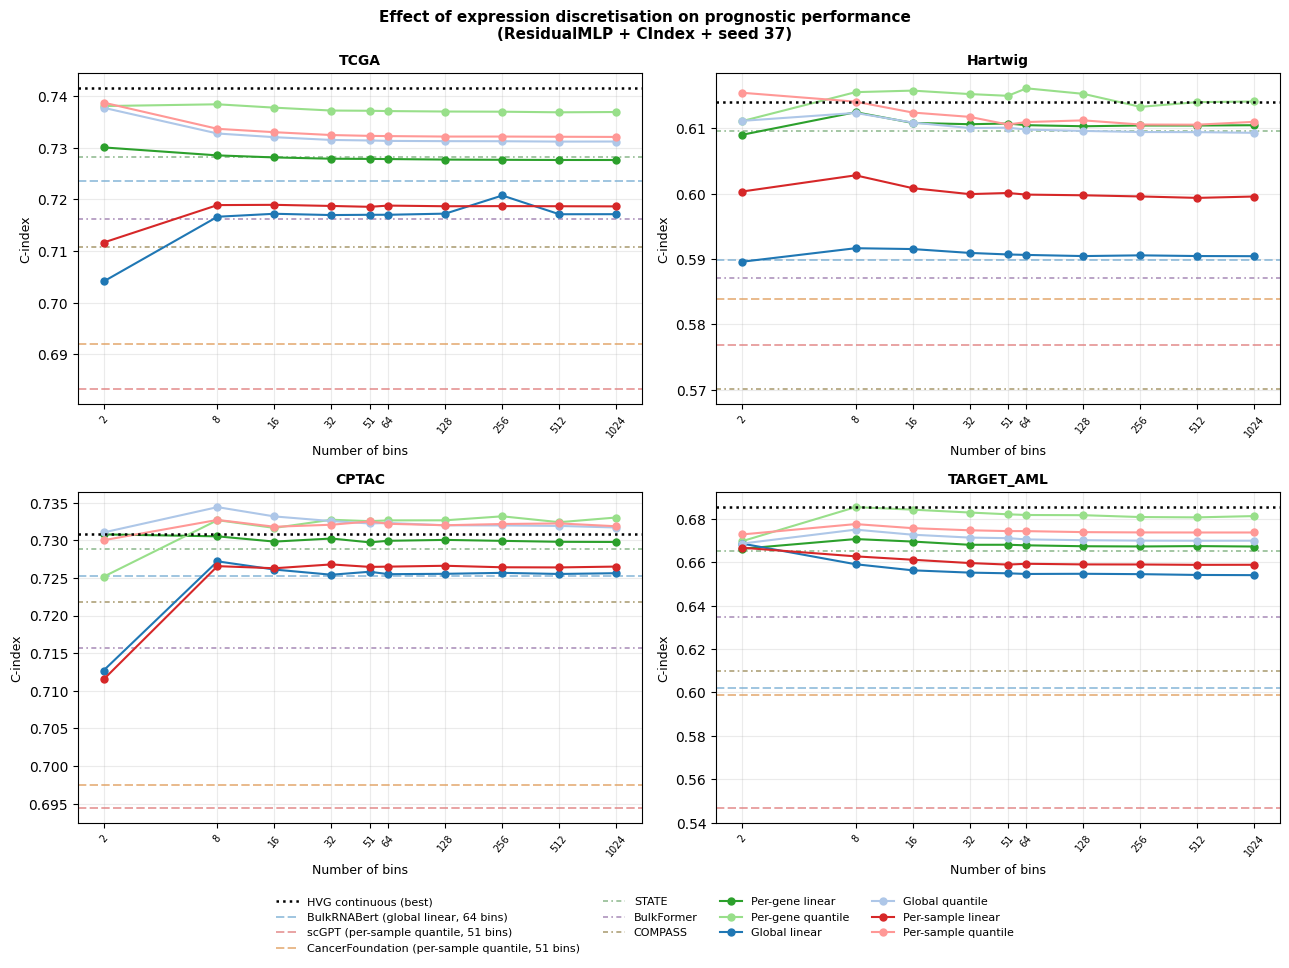

In [87]:
import matplotlib.ticker as mticker

# Muted FM palette — distinct from the strategy line colors
FM_STYLE = {
    "BulkRNABert":      dict(color="#7bafd4", ls=(0,(5,2)),   lw=1.2, label="BulkRNABert (global linear, 64 bins)"),
    "scGPT":            dict(color="#e08080", ls=(0,(5,2)),   lw=1.2, label="scGPT (per-sample quantile, 51 bins)"),
    "CancerFoundation": dict(color="#e0a060", ls=(0,(5,2)),   lw=1.2, label="CancerFoundation (per-sample quantile, 51 bins)"),
    "STATE":            dict(color="#80b080", ls=(0,(3,2,1,2)),lw=1.2, label="STATE"),
    "BulkFormer":       dict(color="#a080b0", ls=(0,(3,2,1,2)),lw=1.2, label="BulkFormer"),
    "COMPASS":          dict(color="#a09060", ls=(0,(3,2,1,2)),lw=1.2, label="COMPASS"),
}

# Load FM performance per dataset from agg_filtered CSVs
fm_perf = {}
for ds in DATASETS:
    df = pd.read_csv(OUT_DIR / "transcriptomic" / f"{ds}_survival_PFS_agg_filtered.csv")
    df["overall_mean"] = pd.to_numeric(df["overall_mean"], errors="coerce")
    fm_perf[ds] = {
        fm: float(df[df["RNA_key"] == fm]["overall_mean"].max())
        for fm in FM_STYLE
        if not df[df["RNA_key"] == fm].empty
    }

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey=False)
axes_flat = axes.flatten()

for ax, ds in zip(axes_flat, DATASETS):
    baseline_mean = hvg_best.loc[ds, "overall_mean"]

    # Continuous HVG baseline — just a line, no band
    ax.axhline(baseline_mean, color="black", ls=":", lw=1.8, zorder=4,
               label="HVG continuous (best)")

    # FM reference horizontals (drawn behind strategy lines)
    for fm, style in FM_STYLE.items():
        if fm in fm_perf.get(ds, {}):
            ax.axhline(fm_perf[ds][fm],
                       color=style["color"], ls=style["ls"], lw=style["lw"],
                       alpha=0.85, zorder=2, label=style["label"])

    # Binning strategy convergence curves
    sub = binned_agg[binned_agg["dataset"] == ds]
    for strategy, style in STRATEGY_STYLE.items():
        rows = sub[sub["bin_strategy"] == strategy].set_index("n_bins")
        ys   = [rows.loc[nb, "mean"] if nb in rows.index else np.nan for nb in N_BINS_ORDER]
        errs = [rows.loc[nb, "std"]  if nb in rows.index else np.nan for nb in N_BINS_ORDER]
        ax.errorbar(N_BINS_ORDER, ys,
                    color=style["color"], marker=style["marker"],
                    ls=style["ls"], lw=1.5, ms=5, capsize=3, zorder=3,
                    label=style["label"])

    ax.set_xscale("log", base=2)
    ax.xaxis.set_major_formatter(mticker.ScalarFormatter())
    ax.set_xticks(N_BINS_ORDER)
    ax.tick_params(axis="x", rotation=50, labelsize=7)
    ax.set_xlabel("Number of bins", fontsize=9)
    ax.set_ylabel("C-index", fontsize=9)
    ax.set_title(ds, fontsize=10, fontweight="bold")
    ax.grid(True, alpha=0.25)

# Shared legend — FMs first, then strategies, then baseline
handles, labels = axes_flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4,
           bbox_to_anchor=(0.5, -0.08), fontsize=8, frameon=False)

fig.suptitle(
    "Effect of expression discretisation on prognostic performance\n"
    f"(ResidualMLP + CIndex + seed {BINNED_SEED})",
    fontsize=11, fontweight="bold"
)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "binned_HVG_ablation.png", bbox_inches="tight", dpi=150)
plt.show()

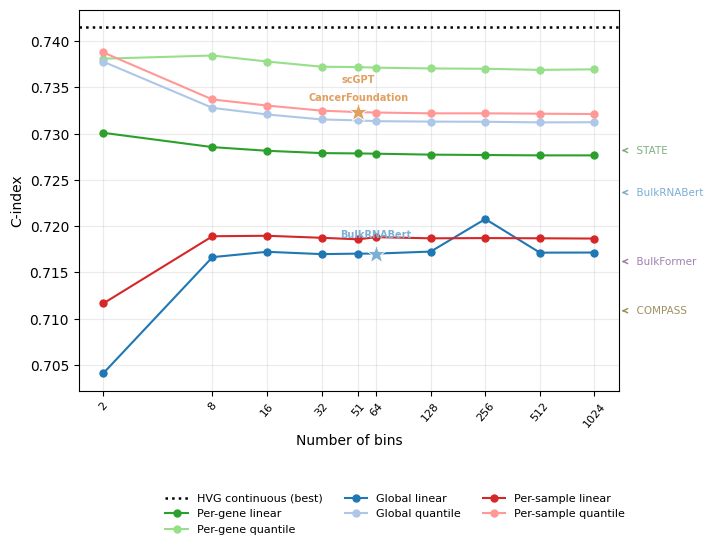

In [88]:
import matplotlib.ticker as mticker

# (strategy, n_bins, label_y_offset_points)
FM_POINTS = {
    "scGPT":            ("per_sample_quantile", 51, (0, 20)),
    "CancerFoundation": ("per_sample_quantile", 51, (0,  7)),
    "BulkRNABert":      ("global_linear",       64, (0, 10)),
}

fig, ax = plt.subplots(1, 1, figsize=(8, 5.5))

ds = "TCGA"
baseline_mean = hvg_best.loc[ds, "overall_mean"]

ax.axhline(baseline_mean, color="black", ls=":", lw=1.8, zorder=4,
           label="HVG continuous (best)")

sub = binned_agg[binned_agg["dataset"] == ds]
for strategy, style in STRATEGY_STYLE.items():
    rows = sub[sub["bin_strategy"] == strategy].set_index("n_bins")
    ys   = [rows.loc[nb, "mean"] if nb in rows.index else np.nan for nb in N_BINS_ORDER]
    ax.plot(N_BINS_ORDER, ys,
            color=style["color"], marker=style["marker"],
            ls=style["ls"], lw=1.5, ms=5, zorder=3,
            label=style["label"])

# ── Stars at FM operating points on the ablation curves ───────────────────
for fm, (strategy, n_bins, offset) in FM_POINTS.items():
    rows = sub[sub["bin_strategy"] == strategy].set_index("n_bins")
    if n_bins not in rows.index:
        continue
    y  = rows.loc[n_bins, "mean"]
    fc = FM_STYLE[fm]["color"] if fm != "scGPT" else FM_STYLE["CancerFoundation"]["color"]  # use same color/style for these two since they overlap
    ax.plot(n_bins, y, marker="*", ms=14, color=fc,
            markeredgecolor="white", markeredgewidth=0.6,
            zorder=5, clip_on=False)
    ax.annotate(
        fm, xy=(n_bins, y), xytext=offset,
        textcoords="offset points",
        fontsize=7, color=fc, ha="center", va="bottom",
        fontweight="bold",
    )
# ──────────────────────────────────────────────────────────────────────────

ax.set_xscale("log", base=2)
ax.xaxis.set_major_formatter(mticker.ScalarFormatter())
ax.set_xticks(N_BINS_ORDER)
ax.tick_params(axis="x", rotation=50, labelsize=8)
ax.set_xlabel("Number of bins", fontsize=10)
ax.set_ylabel("C-index", fontsize=10)
#ax.set_title("TCGA", fontsize=12, fontweight="bold")
ax.grid(True, alpha=0.25)

# ── FM arrows on the right pointing to actual FM performance ──────────────
y_lim = ax.get_ylim()
visible_fms = sorted(
    [(fm, val) for fm, val in fm_perf.get(ds, {}).items()
     if fm in FM_STYLE and y_lim[0] <= val <= y_lim[1]],
    key=lambda x: x[1]
)

min_gap = (y_lim[1] - y_lim[0]) * 0.04
label_y = []
for fm, val in visible_fms:
    pos = val
    for prev in label_y:
        if abs(pos - prev) < min_gap:
            pos = prev + min_gap
    label_y.append(pos)

for (fm, val), pos in zip(visible_fms, label_y):
    style = FM_STYLE[fm] if fm != "scGPT" else FM_STYLE["CancerFoundation"]  # use same color/style for these two since they overlap
    ax.annotate(
        f"  {fm}",
        xy=(1.0, val),
        xycoords=("axes fraction", "data"),
        xytext=(1.02, pos),
        textcoords=("axes fraction", "data"),
        arrowprops=dict(arrowstyle="->", color=style["color"],
                        lw=1.1, connectionstyle="arc3,rad=0.0"),
        fontsize=7.5, va="center", ha="left",
        color=style["color"], clip_on=False,
    )
# ──────────────────────────────────────────────────────────────────────────

handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3,
           bbox_to_anchor=(0.5, 0), fontsize=8, frameon=False)
'''
fig.suptitle(
    "Effect of expression discretisation on prognostic performance — TCGA\n"
    f"(ResidualMLP + CIndex + seed {BINNED_SEED})",
    fontsize=10, fontweight="bold"
)
'''
plt.tight_layout()
plt.subplots_adjust(right=0.78, bottom=0.28)
plt.savefig(FIGURE_DIR / "binned_HVG_ablation_TCGA.png", bbox_inches="tight", dpi=150)
plt.show()

In [89]:
rows = []
for fm, (strategy, n_bins, _) in FM_POINTS.items():
    # Performance of binned HVG at the FM's operating point
    sub_fm = binned_agg[
        (binned_agg["dataset"] == ds) &
        (binned_agg["bin_strategy"] == strategy) &
        (binned_agg["n_bins"] == n_bins)
    ]
    binned_mean = sub_fm["mean"].values[0] if len(sub_fm) else float("nan")
    binned_std  = sub_fm["std"].values[0]  if len(sub_fm) else float("nan")

    # Actual FM performance
    fm_mean = fm_perf.get(ds, {}).get(fm, float("nan"))

    rows.append({
        "Model":            fm,
        "Bin strategy":     strategy,
        "n_bins":           n_bins,
        "HVG w/ binning":   f"{binned_mean:.3f} ± {binned_std:.3f}",
        "Actual FM":        f"{fm_mean:.3f}",
        "Gap (FM − binned)": f"{fm_mean - binned_mean:+.3f}",
    })

df_compare = pd.DataFrame(rows).set_index("Model")
print(df_compare.to_string())

                         Bin strategy  n_bins HVG w/ binning Actual FM Gap (FM − binned)
Model                                                                                   
scGPT             per_sample_quantile      51  0.732 ± 0.012     0.683            -0.049
CancerFoundation  per_sample_quantile      51  0.732 ± 0.012     0.692            -0.040
BulkRNABert             global_linear      64  0.717 ± 0.003     0.724            +0.007


### Foundation Model Finetuning

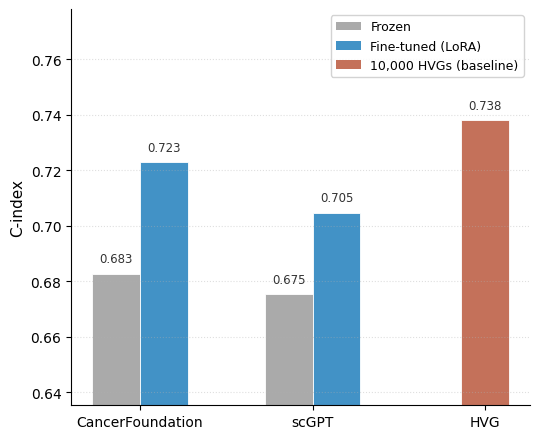

In [92]:
from matplotlib.lines import Line2D

# ── load ──────────────────────────────────────────────────────────────────────
ft   = pd.read_csv("../model_outputs_finetune/TCGA/survival/PFS/finetune_metrics.csv")
orig = pd.read_csv("../model_outputs/TCGA/survival/PFS/all_metrics.csv")

SHOW_FMS = ['CancerFoundation', 'scGPT']

# ── aggregate ─────────────────────────────────────────────────────────────────
ft_filt   = ft[(ft["loss"] == "CIndex") & (ft["seed"] == 37) & ft["fm_name"].isin(SHOW_FMS)]
orig_filt = orig[(orig["arch"] == "Linear") & (orig["loss"] == "CIndex") & (orig["seed"] == 37)]

orig_mean       = orig_filt.groupby("RNA_key")["overall"].mean()
ft_mean_by_mode = ft_filt.groupby(["fm_name", "ft_mode"])["overall"].mean()
hvg_mean = (
    orig[
        (orig["RNA_key"] == "RNA_seq") &
        (orig["nHVGs"] == 10000) &         # best nHVGs for Linear + CIndex on TCGA
        (orig["loss"] == BINNED_LOSS) &
        (orig["arch"] == "Linear") &
        (orig["seed"] == 37)
    ]["overall"].mean()
)

# ── groups & colors ───────────────────────────────────────────────────────────
COLORS = {"Frozen": "#AAAAAA", "LoRA": "#4292C6", "HVG": "#C4715A"}

groups = []
for fm in SHOW_FMS:
    groups.append((fm, [
        ("Frozen", orig_mean.get(fm, np.nan),                    COLORS["Frozen"]),
        ("LoRA",   ft_mean_by_mode.get((fm, "LoRA"), np.nan),    COLORS["LoRA"]),
    ]))
groups.append(("HVG", [("HVG", hvg_mean, COLORS["HVG"])]))

# ── x positions ───────────────────────────────────────────────────────────────
w, group_gap = 0.28, 0.45
flat_bars, x_centers, cur_x = [], [], 0.0

for g_label, bars in groups:
    n       = len(bars)
    offsets = (np.arange(n) - (n - 1) / 2) * w
    for (b_label, val, color), offset in zip(bars, offsets):
        flat_bars.append((cur_x + offset, val, color, b_label))
    x_centers.append(cur_x)
    cur_x += n * w + group_gap

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(5.5, 4.5))

seen = set()
for x, val, color, b_label in flat_bars:
    lbl = b_label if b_label not in seen else "_nolegend_"
    seen.add(b_label)
    ax.bar(x, val if not np.isnan(val) else 0, w,
           color=color, label=lbl, edgecolor='white', linewidth=0.6)
    if not np.isnan(val):
        ax.text(x, val + 0.003, f"{val:.3f}",
                ha='center', va='bottom', fontsize=8.5, color='#333333')

all_vals = [v for _, v, _, _ in flat_bars if not np.isnan(v)]
ax.set_ylim(min(all_vals) - 0.04, max(all_vals) + 0.04)
ax.set_ylabel("C-index", fontsize=11)
#ax.set_title("Frozen vs. fine-tuned — TCGA PFS", fontsize=12, fontweight='bold')
ax.set_xticks(x_centers)
ax.set_xticklabels([g[0] for g in groups], fontsize=10)
ax.grid(axis='y', ls=':', alpha=0.4)
ax.spines[['top', 'right']].set_visible(False)

legend_handles = [
    mpatches.Patch(facecolor=COLORS["Frozen"], label="Frozen"),
    mpatches.Patch(facecolor=COLORS["LoRA"],   label="Fine-tuned (LoRA)"),
    mpatches.Patch(facecolor=COLORS["HVG"],    label="10,000 HVGs (baseline)"),
]
ax.legend(handles=legend_handles, fontsize=9, framealpha=0.85, loc='upper right')

plt.tight_layout()
plt.savefig(FIGURE_DIR / "finetune_comparison.png", dpi=300, bbox_inches='tight')
plt.show()
